# Independent ERA5 wind-collocation review

This notebook independently reads cached ERA5 NetCDF files and processed Zarr archives. It does not read credentials, make requests, modify input files, or rely on variables from another notebook. All vector conventions use eastward and northward components in m s$^{-1}$.

The original analysis is audited from its saved code and outputs, then the matchup, interpolation, filtering and statistics are recomputed from disk.

In [1]:
from pathlib import Path
import hashlib
import json
import platform
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import display

REPO_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
NOTEBOOK_PATH = REPO_ROOT / 'notebooks/012_era5_wind_collocation_review.ipynb'
SOURCE_NOTEBOOK_PATH = REPO_ROOT / 'notebooks/00_paper_results.ipynb'
MATCHED_ZARR_PATH = REPO_ROOT / 'data/processed/swot_hfradar_zarr_matches.zarr'
ERA5_DIR = REPO_ROOT / 'data/raw/era5_hfradar_domain'
ERA5_FILES = sorted(ERA5_DIR.glob('era5_agulhas_*.nc'))

assert SOURCE_NOTEBOOK_PATH.is_file()
assert MATCHED_ZARR_PATH.is_dir()
assert ERA5_FILES, f'No cached ERA5 files found in {ERA5_DIR}'

# Read-only policy: only local reads occur below. No CDS, requests, credential-file
# access, archive writes, or execution of source-notebook cells is permitted.

def sha256(path):
    digest = hashlib.sha256()
    with path.open('rb') as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()


def local_file_record(path):
    stat = path.stat()
    return {
        'file': str(path.relative_to(REPO_ROOT)),
        'size_bytes': stat.st_size,
        'modified': pd.Timestamp(stat.st_mtime, unit='s').isoformat(),
        'sha256': sha256(path),
    }

run_metadata = {
    'python': sys.version.split()[0],
    'platform': platform.platform(),
    'numpy': np.__version__,
    'pandas': pd.__version__,
    'xarray': xr.__version__,
    'matplotlib': plt.matplotlib.__version__,
    'cached_era5_file_count': len(ERA5_FILES),
}
print(json.dumps(run_metadata, indent=2))
print('ERA5 file inventory (hashes are over local files):')
display(pd.DataFrame([local_file_record(path) for path in ERA5_FILES]))

{
  "python": "3.11.15",
  "platform": "macOS-15.6.1-arm64-arm-64bit",
  "numpy": "2.4.6",
  "pandas": "3.0.5",
  "xarray": "2026.7.0",
  "matplotlib": "3.11.1",
  "cached_era5_file_count": 12
}
ERA5 file inventory (hashes are over local files):


,file,size_bytes,modified,sha256
0,data/raw/era5_hfradar_domain/era5_agulhas_2024...,326576,2026-10-08T10:39:48.443002224,9d28ba4423ff443fc7c16ad17bb0f36ab08667e09cce5e...
1,data/raw/era5_hfradar_domain/era5_agulhas_2025...,411633,2026-10-08T10:41:08.361461163,9a8993169ac6e5753e2c704c125ef70d44f80da3cda5dd...
2,data/raw/era5_hfradar_domain/era5_agulhas_2025...,332165,2026-10-08T10:41:37.443148613,fef28f8b6226e6d6ca35b5ddbfd3eccb9ab4816501efa1...
3,data/raw/era5_hfradar_domain/era5_agulhas_2025...,425889,2026-10-08T10:42:05.101410627,681ede94a8d4a444a7de3efec23e4cf9d8fecc7935032d...
4,data/raw/era5_hfradar_domain/era5_agulhas_2025...,416853,2026-10-08T10:42:28.267221928,9cf1025e5185f3966f83cc16b1580a8ce04851a68167df...
5,data/raw/era5_hfradar_domain/era5_agulhas_2025...,807114,2026-10-08T10:43:50.081110477,f5ce4df616d7b19237bfddd21e1e8e2c773ee6872184ad...
6,data/raw/era5_hfradar_domain/era5_agulhas_2025...,425287,2026-10-08T10:44:27.395027399,013c80bf7e7fed04cb5d9aa0cfa2d91df377d748cebebe...
7,data/raw/era5_hfradar_domain/era5_agulhas_2025...,701861,2026-10-08T10:47:02.991892815,d5713ba270562c74be71f6ebe0c9ae85ef1d60607028be...
8,data/raw/era5_hfradar_domain/era5_agulhas_2025...,502700,2026-10-08T10:47:38.868162394,a71283fd74af5d10b1c96346782da95cfb615827f96f02...
9,data/raw/era5_hfradar_domain/era5_agulhas_2025...,517146,2026-10-08T10:48:16.293048382,977b9058080b279e59fb4225c6d6492bec4f886d36ab2c...


## 2–3. Audit the original wind analysis and matchup construction

Read cells 51–53 as notebook JSON, including saved outputs, then locate the code that constructs and writes the matched Zarr archive. This documents the original claims and assumptions without running the original notebook or importing its kernel state.

In [2]:
import nbformat
from io import StringIO

source_nb = nbformat.read(SOURCE_NOTEBOOK_PATH, as_version=4)
source_cells = source_nb.cells
wind_cells = source_cells[50:53]
assert len(wind_cells) == 3


def output_summary(cell):
    parts = []
    for output in cell.get('outputs', []):
        output_type = output.get('output_type', '')
        data = output.get('data', {})
        text = output.get('text', data.get('text/plain', ''))
        if isinstance(text, list):
            text = ''.join(text)
        if text:
            parts.append(f'{output_type}: {str(text).strip()[:500]}')
        elif 'image/png' in data:
            parts.append(f'{output_type}: saved image/png output')
    return '\n'.join(parts) if parts else '(no saved output)'


source_audit_rows = []
for cell_number, cell in enumerate(wind_cells, start=51):
    code = cell.get('source', '')
    source_audit_rows.append({
        'source_cell': cell_number,
        'execution_count': cell.get('execution_count'),
        'code_excerpt': code[:500].replace('\n', ' '),
        'saved_output_summary': output_summary(cell),
    })
source_audit = pd.DataFrame(source_audit_rows)
display(source_audit)

original_class_candidates = []
original_speed_candidates = []
for output in wind_cells[1].get('outputs', []):
    html = output.get('data', {}).get('text/html')
    if not html:
        continue
    try:
        tables = pd.read_html(StringIO(''.join(html) if isinstance(html, list) else html))
    except ValueError:
        continue
    for table in tables:
        if isinstance(table.columns, pd.MultiIndex):
            table.columns = [str(column[0]) for column in table.columns]
        required_class_columns = {'n', 'mean_swot_speed_m_s', 'median_swot_speed_m_s', 'mean_bias_swot_minus_hf_m_s'}
        if len(table) == 2 and required_class_columns.issubset(table.columns):
            original_class_candidates.append(table.copy())
        if {'wind_class', 'swot_speed_bin_m_s', 'n'}.issubset(table.columns):
            original_speed_candidates.append(table.copy())
assert original_class_candidates, 'Saved cell 52 has no parseable two-class summary.'
original_class_table = original_class_candidates[0]
if 'wind_class' not in original_class_table.columns:
    original_class_table = original_class_table.rename(columns={original_class_table.columns[0]: 'wind_class'})
original_class_table['wind_class'] = original_class_table['wind_class'].astype(str)
original_class_table = original_class_table.set_index('wind_class')
original_speed_bin_table = original_speed_candidates[0] if original_speed_candidates else pd.DataFrame()
print('Original saved class summary (two wind classes, from cell 52 output):')
display(original_class_table)
print('Original saved speed-bin summary (from cell 52 output):')
display(original_speed_bin_table)

archive_writer_cells = []
for cell_number, cell in enumerate(source_cells, start=1):
    code = cell.get('source', '')
    if 'swot_hfradar_zarr_matches.zarr' in code and 'to_zarr' in code:
        archive_writer_cells.append({
            'source_cell': cell_number,
            'relevant_lines': '\n'.join(
                line for line in code.splitlines()
                if any(token in line for token in (
                    'MAX_RADAR_TIME_GAP', 'argmin', 'time_gap', 'comparison_mask',
                    'matched_swot_times', 'matched_radar_times', 'to_zarr',
                    'binned_statistic_2d', 'MIN_SWOT_PIXELS_PER_RADAR_CELL',
                ))
            ),
        })
archive_construction_audit = pd.DataFrame(archive_writer_cells)
display(archive_construction_audit)
assert not archive_construction_audit.empty, 'No archive-construction cell was located.'
print('Audit boundaries: source cells are parsed only; their code is never executed.')

,source_cell,execution_count,code_excerpt,saved_output_summary
0,51,1,# Download only the ERA5 hours and domain need...,"stream: 2026-10-08 12:38:56,331 INFO [2026-10-..."
1,52,2,# Collocate ERA5 winds and reproduce the speed...,display_data: n mean_swot_speed_m_s median_s...
2,53,3,# Quantify the descriptive shift from opposing...,display_data: Following minus opposing\nmean_s...


Original saved class summary (two wind classes, from cell 52 output):


,n,mean_swot_speed_m_s,median_swot_speed_m_s,mean_hf_speed_m_s,median_hf_speed_m_s,mean_bias_swot_minus_hf_m_s,median_bias_swot_minus_hf_m_s,bias_q25_m_s,bias_q75_m_s,mean_along_current_wind_m_s,median_along_current_wind_m_s
wind_class,,,,,,,,,,,
Following,3321,0.768,0.53,0.913,0.798,-0.145,-0.158,-0.362,0.033,5.325,4.266
Opposing,2955,0.681,0.48,0.724,0.573,-0.043,-0.033,-0.226,0.135,-5.891,-5.923


Original saved speed-bin summary (from cell 52 output):


,Unnamed: 0,wind_class,swot_speed_bin_m_s,n,mean_bias_swot_minus_hf_m_s,median_bias_swot_minus_hf_m_s
0,0,Following,0-0.25,889,-0.212638,-0.172447
1,1,Following,0.25-0.5,720,-0.205972,-0.166946
2,2,Following,0.5-0.75,456,-0.273583,-0.275217
3,3,Following,0.75-1.0,256,-0.295430,-0.313475
4,4,Following,1.0-1.5,504,-0.168340,-0.157327
5,5,Following,1.5-2.0,276,0.028167,-0.010839
6,6,Following,2+,220,0.608478,0.557919
7,7,Opposing,0-0.25,784,-0.149030,-0.111303
8,8,Opposing,0.25-0.5,734,-0.068211,0.007821
9,9,Opposing,0.5-0.75,337,-0.012490,0.031074


,source_cell,relevant_lines
0,13,from scipy.stats import binned_statistic_2d\nM...
1,32,comparison_mask = matched.comparison_mask....


Audit boundaries: source cells are parsed only; their code is never executed.


In [3]:
original_class_table = original_class_table.reset_index()

In [4]:
AUDIT_INPUT_FILES = [
    SOURCE_NOTEBOOK_PATH,
    MATCHED_ZARR_PATH / 'zarr.json',
    *ERA5_FILES,
]
AUDIT_INPUT_FILES = [path for path in AUDIT_INPUT_FILES if path.is_file()]
INITIAL_INPUT_FINGERPRINTS = {
    str(path): {'sha256': sha256(path), 'modified_ns': path.stat().st_mtime_ns}
    for path in AUDIT_INPUT_FILES
}
print(f'Fingerprint baseline captured for {len(INITIAL_INPUT_FINGERPRINTS)} local source/metadata files.')

Fingerprint baseline captured for 14 local source/metadata files.


## 4–5. Inspect the matched Zarr and cached ERA5 inputs

Report archive attributes, variable and coordinate dimensions, units, data types, coordinate ordering and source-file time coverage. ERA5 coordinates are normalised and sorted before interpolation; original orientation and duplicate times are recorded before normalisation.

In [5]:
MATCHED = xr.open_zarr(MATCHED_ZARR_PATH, consolidated=True, chunks=None).load()
print('Matched archive attributes:')
display(pd.Series(MATCHED.attrs, name='value').to_frame())

variable_meanings = {
    'swot_time': 'Representative SWOT overpass time stored in the matchup record.',
    'radar_time': 'HF-radar snapshot selected as nearest to swot_time during archive construction.',
    'ugos_coarsened_masked': 'Eastward SWOT geostrophic velocity, coarsened to the HF grid.',
    'vgos_coarsened_masked': 'Northward SWOT geostrophic velocity, coarsened to the HF grid.',
    'ewct_masked': 'Eastward HF-radar surface velocity.',
    'nsct_masked': 'Northward HF-radar surface velocity.',
    'comparison_mask': 'Stored boolean mask for cells meeting the archive comparison criteria.',
}

inspection_rows = []
for name, meaning in variable_meanings.items():
    variable = MATCHED[name]
    inspection_rows.append({
        'name': name,
        'meaning': meaning,
        'dims': variable.dims,
        'shape': variable.shape,
        'dtype': str(variable.dtype),
        'units': variable.attrs.get('units', '(not recorded)'),
        'long_name': variable.attrs.get('long_name', '(not recorded)'),
        'attrs': dict(variable.attrs),
    })
matched_variable_audit = pd.DataFrame(inspection_rows).set_index('name')
display(matched_variable_audit)

assert MATCHED['comparison_mask'].dims == ('match', 'latitude', 'longitude')
for variable_name in ('ugos_coarsened_masked', 'vgos_coarsened_masked', 'ewct_masked', 'nsct_masked'):
    assert MATCHED[variable_name].dims == ('match', 'latitude', 'longitude')
    assert MATCHED[variable_name].shape == MATCHED['comparison_mask'].shape
assert MATCHED['swot_time'].dims == ('match',)
assert MATCHED['radar_time'].dims == ('match',)

matched_latitude = np.asarray(MATCHED['latitude'].values, dtype=float)
matched_longitude = np.asarray(MATCHED['longitude'].values, dtype=float)

def coordinate_orientation(values):
    differences = np.diff(values)
    if np.all(differences > 0):
        return 'ascending'
    if np.all(differences < 0):
        return 'descending'
    return 'non-monotonic or duplicate'

assert coordinate_orientation(matched_latitude) in ('ascending', 'descending')
assert coordinate_orientation(matched_longitude) in ('ascending', 'descending')
print(f"Matched shape: {MATCHED['comparison_mask'].shape}; latitude {coordinate_orientation(matched_latitude)}; "
      f"longitude {coordinate_orientation(matched_longitude)}")


def normalise_era5_dataset(dataset):
    rename = {}
    for old, new in (('valid_time', 'time'), ('lat', 'latitude'), ('lon', 'longitude')):
        if old in dataset.coords and new not in dataset.coords:
            rename[old] = new
    if rename:
        dataset = dataset.rename(rename)
    variable_rename = {}
    for old, new in (
        ('10m_u_component_of_wind', 'u10'),
        ('10m_v_component_of_wind', 'v10'),
    ):
        if old in dataset.data_vars and new not in dataset.data_vars:
            variable_rename[old] = new
    if variable_rename:
        dataset = dataset.rename(variable_rename)
    if 'expver' in dataset.dims:
        dataset = dataset.isel(expver=0, drop=True)
    missing = {'u10', 'v10'} - set(dataset.data_vars)
    if missing:
        raise KeyError(f'ERA5 file missing variables: {sorted(missing)}')
    return dataset[['u10', 'v10']]


era_parts = []
era_file_rows = []
for era_path in ERA5_FILES:
    with xr.open_dataset(era_path) as raw_era:
        raw_lat_name = 'latitude' if 'latitude' in raw_era.coords else 'lat'
        raw_lon_name = 'longitude' if 'longitude' in raw_era.coords else 'lon'
        raw_time_name = 'time' if 'time' in raw_era.coords else 'valid_time'
        raw_lat = np.asarray(raw_era[raw_lat_name].values, dtype=float)
        raw_lon = np.asarray(raw_era[raw_lon_name].values, dtype=float)
        normalized = normalise_era5_dataset(raw_era).load()
        file_times = pd.DatetimeIndex(pd.to_datetime(normalized['time'].values))
        era_file_rows.append({
            'file': era_path.name,
            'time_count': len(file_times),
            'time_min': file_times.min() if len(file_times) else pd.NaT,
            'time_max': file_times.max() if len(file_times) else pd.NaT,
            'raw_time_coordinate': raw_time_name,
            'raw_latitude_orientation': coordinate_orientation(raw_lat),
            'raw_longitude_orientation': coordinate_orientation(raw_lon),
            'raw_latitude_bounds': (float(np.nanmin(raw_lat)), float(np.nanmax(raw_lat))),
            'raw_longitude_bounds': (float(np.nanmin(raw_lon)), float(np.nanmax(raw_lon))),
            'u10_units': raw_era['u10'].attrs.get('units', '(not recorded)') if 'u10' in raw_era else raw_era['10m_u_component_of_wind'].attrs.get('units', '(not recorded)'),
            'v10_units': raw_era['v10'].attrs.get('units', '(not recorded)') if 'v10' in raw_era else raw_era['10m_v_component_of_wind'].attrs.get('units', '(not recorded)'),
        })
        era_parts.append(normalized)

era_file_audit = pd.DataFrame(era_file_rows)
display(era_file_audit)
ERA5_RAW_TIMES = pd.DatetimeIndex(np.concatenate([part['time'].values for part in era_parts]))
ERA5_RAW_DUPLICATE_TIMES = ERA5_RAW_TIMES[ERA5_RAW_TIMES.duplicated()]
ERA5_DS = xr.concat(era_parts, dim='time', data_vars='all', coords='minimal', compat='override', join='exact')
ERA5_DS = ERA5_DS.sortby('time')
ERA5_DS = ERA5_DS.drop_duplicates(dim='time', keep='first')
ERA5_DS = ERA5_DS.sortby('latitude').sortby('longitude').transpose('time', 'latitude', 'longitude').load()
ERA5_TIMES = pd.DatetimeIndex(pd.to_datetime(ERA5_DS['time'].values))
ERA5_LATITUDE = np.asarray(ERA5_DS['latitude'].values, dtype=float)
ERA5_LONGITUDE = np.asarray(ERA5_DS['longitude'].values, dtype=float)

assert ERA5_DS['u10'].dims == ('time', 'latitude', 'longitude')
assert ERA5_DS['v10'].dims == ('time', 'latitude', 'longitude')
assert coordinate_orientation(ERA5_LATITUDE) == 'ascending'
assert coordinate_orientation(ERA5_LONGITUDE) == 'ascending'
assert ERA5_TIMES.is_monotonic_increasing and ERA5_TIMES.is_unique
print('ERA5 combined structure:')
print(ERA5_DS)
print(f'Raw time records: {len(ERA5_RAW_TIMES)}; duplicate records removed: {len(ERA5_RAW_DUPLICATE_TIMES)}')
print(f'ERA5 time range: {ERA5_TIMES.min()} to {ERA5_TIMES.max()}')
print(f'ERA5 latitude range: {ERA5_LATITUDE.min()} to {ERA5_LATITUDE.max()} degrees; '
      f'longitude range: {ERA5_LONGITUDE.min()} to {ERA5_LONGITUDE.max()} degrees')
print(f"u10 units: {ERA5_DS['u10'].attrs.get('units', '(not recorded)')}; "
      f"v10 units: {ERA5_DS['v10'].attrs.get('units', '(not recorded)')}")

Matched archive attributes:


,value


,meaning,dims,shape,dtype,units,long_name,attrs
name,,,,,,,
swot_time,Representative SWOT overpass time stored in th...,"(match,)","(35,)",datetime64[ns],(not recorded),(not recorded),{}
radar_time,HF-radar snapshot selected as nearest to swot_...,"(match,)","(35,)",datetime64[ns],(not recorded),(not recorded),{}
ugos_coarsened_masked,"Eastward SWOT geostrophic velocity, coarsened ...","(match, latitude, longitude)","(35, 75, 150)",float32,(not recorded),(not recorded),{}
vgos_coarsened_masked,"Northward SWOT geostrophic velocity, coarsened...","(match, latitude, longitude)","(35, 75, 150)",float32,(not recorded),(not recorded),{}
ewct_masked,Eastward HF-radar surface velocity.,"(match, latitude, longitude)","(35, 75, 150)",float32,(not recorded),(not recorded),{}
nsct_masked,Northward HF-radar surface velocity.,"(match, latitude, longitude)","(35, 75, 150)",float32,(not recorded),(not recorded),{}
comparison_mask,Stored boolean mask for cells meeting the arch...,"(match, latitude, longitude)","(35, 75, 150)",bool,(not recorded),(not recorded),{}


Matched shape: (35, 75, 150); latitude ascending; longitude ascending


,file,time_count,time_min,time_max,raw_time_coordinate,raw_latitude_orientation,raw_longitude_orientation,raw_latitude_bounds,raw_longitude_bounds,u10_units,v10_units
0,era5_agulhas_202411.nc,72,2024-11-10,2024-11-12 23:00:00,valid_time,descending,ascending,"(-38.0, -33.25)","(18.5, 29.25)",m s**-1,m s**-1
1,era5_agulhas_202503.nc,96,2025-03-13,2025-03-16 23:00:00,valid_time,descending,ascending,"(-38.0, -33.25)","(18.5, 29.25)",m s**-1,m s**-1
2,era5_agulhas_202504.nc,72,2025-04-25,2025-04-27 23:00:00,valid_time,descending,ascending,"(-38.0, -33.25)","(18.5, 29.25)",m s**-1,m s**-1
3,era5_agulhas_202506.nc,96,2025-06-05,2025-06-08 23:00:00,valid_time,descending,ascending,"(-38.0, -33.25)","(18.5, 29.25)",m s**-1,m s**-1
4,era5_agulhas_202507.nc,96,2025-07-17,2025-07-20 23:00:00,valid_time,descending,ascending,"(-38.0, -33.25)","(18.5, 29.25)",m s**-1,m s**-1
5,era5_agulhas_202508.nc,192,2025-08-07,2025-08-31 23:00:00,valid_time,descending,ascending,"(-38.0, -33.25)","(18.5, 29.25)",m s**-1,m s**-1
6,era5_agulhas_202509.nc,96,2025-09-18,2025-09-21 23:00:00,valid_time,descending,ascending,"(-38.0, -33.25)","(18.5, 29.25)",m s**-1,m s**-1
7,era5_agulhas_202510.nc,168,2025-10-08,2025-10-31 23:00:00,valid_time,descending,ascending,"(-38.0, -33.25)","(18.5, 29.25)",m s**-1,m s**-1
8,era5_agulhas_202511.nc,120,2025-11-01,2025-11-22 23:00:00,valid_time,descending,ascending,"(-38.0, -33.25)","(18.5, 29.25)",m s**-1,m s**-1
9,era5_agulhas_202512.nc,120,2025-12-10,2025-12-31 23:00:00,valid_time,descending,ascending,"(-38.0, -33.25)","(18.5, 29.25)",m s**-1,m s**-1


ERA5 combined structure:
<xarray.Dataset> Size: 10MB
Dimensions:    (time: 1368, latitude: 20, longitude: 44)
Coordinates:
  * time       (time) datetime64[ns] 11kB 2024-11-10 ... 2026-04-17T23:00:00
    expver     (time) <U4 22kB '0001' '0001' '0001' ... '0001' '0001' '0001'
  * latitude   (latitude) float64 160B -38.0 -37.75 -37.5 ... -33.5 -33.25
  * longitude  (longitude) float64 352B 18.5 18.75 19.0 ... 28.75 29.0 29.25
    number     int64 8B 0
Data variables:
    u10        (time, latitude, longitude) float32 5MB -2.153 -2.313 ... 9.528
    v10        (time, latitude, longitude) float32 5MB 3.042 3.059 ... 2.533
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-10-08T10:39 GRIB to CDM+CF via cfgrib-0.9.1...
Raw time records: 1

In [6]:
PROCESSED_DIR = REPO_ROOT / 'data/processed'
SWOT_SOURCE_ZARR = PROCESSED_DIR / 'swot_filtered_velocity.zarr'
HF_SOURCE_ZARR = PROCESSED_DIR / 'hf_radar.zarr'
assert SWOT_SOURCE_ZARR.is_dir() and HF_SOURCE_ZARR.is_dir()
source_swot_indices = np.asarray(MATCHED['source_swot_index'].values, dtype=int)
source_radar_indices = np.asarray(MATCHED['source_radar_index'].values, dtype=int)

with xr.open_zarr(SWOT_SOURCE_ZARR, consolidated=True, chunks=None) as source_swot_ds:
    assert np.all((source_swot_indices >= 0) & (source_swot_indices < source_swot_ds.sizes['time']))
    source_swot_times = pd.DatetimeIndex(pd.to_datetime(source_swot_ds['time'].values[source_swot_indices]))
    swot_source_metadata = {
        name: {
            'dims': source_swot_ds[name].dims,
            'units': source_swot_ds[name].attrs.get('units', '(not recorded)'),
            'attrs': dict(source_swot_ds[name].attrs),
        }
        for name in ('ugos_filtered', 'vgos_filtered')
    }
    assert source_swot_times.equals(pd.DatetimeIndex(pd.to_datetime(MATCHED['swot_time'].values)))

with xr.open_zarr(HF_SOURCE_ZARR, consolidated=True, chunks=None) as source_hf_ds:
    assert np.all((source_radar_indices >= 0) & (source_radar_indices < source_hf_ds.sizes['time']))
    source_radar_times = pd.DatetimeIndex(pd.to_datetime(source_hf_ds['time'].values[source_radar_indices]))
    hf_source_metadata = {
        name: {
            'dims': source_hf_ds[name].dims,
            'units': source_hf_ds[name].attrs.get('units', '(not recorded)'),
            'attrs': dict(source_hf_ds[name].attrs),
        }
        for name in ('ewct', 'nsct')
    }
    assert source_radar_times.equals(pd.DatetimeIndex(pd.to_datetime(MATCHED['radar_time'].values)))
    assert np.array_equal(np.sort(np.asarray(source_hf_ds['latitude'].values)), matched_latitude)
    assert np.array_equal(np.sort(np.asarray(source_hf_ds['longitude'].values)), matched_longitude)

source_velocity_metadata = pd.DataFrame([
    {'source': 'SWOT', 'variable': name, **metadata}
    for name, metadata in swot_source_metadata.items()
] + [
    {'source': 'HF radar', 'variable': name, **metadata}
    for name, metadata in hf_source_metadata.items()
])
display(source_velocity_metadata)
display(pd.DataFrame({
    'source_swot_index': source_swot_indices,
    'stored_swot_time': MATCHED['swot_time'].values,
    'source_swot_time': source_swot_times.values,
    'source_radar_index': source_radar_indices,
    'stored_radar_time': MATCHED['radar_time'].values,
    'source_radar_time': source_radar_times.values,
}).head())
print('All 35 stored source indices resolve exactly to the stored SWOT and radar times and sorted matched radar coordinates.')

,source,variable,dims,units,attrs
0,SWOT,ugos_filtered,"(time, num_lines, num_pixels)",m/s,{'comment': 'Derived from [ssha_filtered] fiel...
1,SWOT,vgos_filtered,"(time, num_lines, num_pixels)",m/s,{'comment': 'Derived from [ssha_filtered] fiel...
2,HF radar,ewct,"(time, latitude, longitude)",m s-1,"{'units': 'm s-1', 'long_name': 'U component o..."
3,HF radar,nsct,"(time, latitude, longitude)",m s-1,"{'units': 'm s-1', 'long_name': 'V component o..."


,source_swot_index,stored_swot_time,source_swot_time,source_radar_index,stored_radar_time,source_radar_time
0,0,2024-11-11 01:22:32.249915776,2024-11-11 01:22:32.249915776,17,2024-11-11 01:30:00,2024-11-11 01:30:00
1,28,2025-03-14 19:04:20.742309888,2025-03-14 19:04:20.742309888,4027,2025-03-14 19:00:00,2025-03-14 19:00:00
2,29,2025-03-15 05:52:29.398112000,2025-03-15 05:52:29.398112000,4049,2025-03-15 06:00:00,2025-03-15 06:00:00
3,42,2025-04-26 12:35:12.560981696,2025-04-26 12:35:12.560981696,5858,2025-04-26 12:30:00,2025-04-26 12:30:00
4,43,2025-04-26 23:23:08.698875392,2025-04-26 23:23:08.698875392,5880,2025-04-26 23:30:00,2025-04-26 23:30:00


All 35 stored source indices resolve exactly to the stored SWOT and radar times and sorted matched radar coordinates.


## 6–9. Audit time selection and independently collocate ERA5 winds

Compare the nearest-hour lookup for `swot_time`, `radar_time` and their midpoint. A match is considered available only within the explicitly set 90-minute tolerance used by the original analysis. Spatial interpolation uses the stored matched-grid latitude/longitude centres and leaves out-of-bounds cells missing. A deterministic set of values is checked against a manual four-neighbour bilinear calculation.

In [7]:
SWOT_TIMES = pd.DatetimeIndex(pd.to_datetime(MATCHED['swot_time'].values))
RADAR_TIMES = pd.DatetimeIndex(pd.to_datetime(MATCHED['radar_time'].values))
MATCH_COUNT = MATCHED.sizes['match']
MATCH_IDS = np.arange(MATCH_COUNT)
TIME_TOLERANCE = pd.Timedelta(minutes=90)

assert len(SWOT_TIMES) == len(RADAR_TIMES) == MATCH_COUNT
assert not SWOT_TIMES.isna().any() and not RADAR_TIMES.isna().any()

MIDPOINT_TIMES = pd.DatetimeIndex(
    ((SWOT_TIMES.asi8 + RADAR_TIMES.asi8) // 2).astype('datetime64[ns]')
)
TIME_STRATEGIES = {
    'SWOT time': SWOT_TIMES,
    'HF-radar time': RADAR_TIMES,
    'SWOT-radar midpoint': MIDPOINT_TIMES,
}


def nearest_era5_lookup(target_times, tolerance=TIME_TOLERANCE):
    target_times = pd.DatetimeIndex(target_times)
    nearest_indices = ERA5_TIMES.get_indexer(target_times, method='nearest')
    in_range = nearest_indices >= 0
    nearest_times_values = np.full(len(target_times), np.datetime64('NaT'), dtype='datetime64[ns]')
    nearest_times_values[in_range] = ERA5_TIMES.values[nearest_indices[in_range]]
    nearest_times = pd.DatetimeIndex(nearest_times_values)
    offset_ns = np.full(len(target_times), np.iinfo(np.int64).max, dtype=np.int64)
    offset_ns[in_range] = np.abs(target_times.asi8[in_range] - nearest_times.asi8[in_range])
    offsets = pd.to_timedelta(offset_ns, unit='ns')
    valid = in_range & ~target_times.isna() & (offsets <= tolerance)
    return nearest_indices, nearest_times, offsets, np.asarray(valid, dtype=bool)


time_rows = []
TIME_LOOKUPS = {}
for strategy_name, target_times in TIME_STRATEGIES.items():
    indices, nearest_times, offsets, valid = nearest_era5_lookup(target_times)
    TIME_LOOKUPS[strategy_name] = (indices, nearest_times, offsets, valid)
    valid_offsets_minutes = offsets[valid].total_seconds() / 60
    time_rows.append({
        'strategy': strategy_name,
        'n_matches': len(target_times),
        'valid_within_90min': int(valid.sum()),
        'missing_or_out_of_tolerance': int((~valid).sum()),
        'offset_min_minutes': float(np.min(valid_offsets_minutes)) if valid.any() else np.nan,
        'offset_median_minutes': float(np.median(valid_offsets_minutes)) if valid.any() else np.nan,
        'offset_max_minutes': float(np.max(valid_offsets_minutes)) if valid.any() else np.nan,
        'offset_q95_minutes': float(np.quantile(valid_offsets_minutes, 0.95)) if valid.any() else np.nan,
        'offsets_over_30min': int((offsets > pd.Timedelta(minutes=30)).sum()),
        'offsets_over_60min': int((offsets > pd.Timedelta(minutes=60)).sum()),
        'offsets_over_90min': int((offsets > TIME_TOLERANCE).sum()),
        'nearest_time_duplicates': int(nearest_times[valid].duplicated().sum()),
        'crosses_month_edge': int(sum(
            target.month != nearest.month
            for target, nearest, is_valid in zip(target_times, nearest_times, valid)
            if is_valid
        )),
    })
time_audit = pd.DataFrame(time_rows).set_index('strategy')
display(time_audit.round(3))
print(f'ERA5 unique sorted times: {len(ERA5_TIMES)}; source duplicates: {len(ERA5_RAW_DUPLICATE_TIMES)}')
print(f'ERA5 coverage: {ERA5_TIMES.min()} to {ERA5_TIMES.max()}')
print(f'Matched SWOT times: {SWOT_TIMES.min()} to {SWOT_TIMES.max()}')
print(f'Matched radar times: {RADAR_TIMES.min()} to {RADAR_TIMES.max()}')

assert ERA5_TIMES.is_unique and ERA5_TIMES.is_monotonic_increasing


def collocate_strategy(target_times):
    indices, nearest_times, offsets, time_valid = nearest_era5_lookup(target_times)
    safe_indices = np.where(indices >= 0, indices, 0)
    selected = ERA5_DS[['u10', 'v10']].isel(
        time=xr.DataArray(safe_indices, dims='match', coords={'match': MATCH_IDS})
    )
    interpolated = selected.interp(
        latitude=xr.DataArray(matched_latitude, dims='latitude'),
        longitude=xr.DataArray(matched_longitude, dims='longitude'),
        method='linear',
    )
    assert interpolated['u10'].dims == ('match', 'latitude', 'longitude')
    assert interpolated['v10'].dims == ('match', 'latitude', 'longitude')
    assert interpolated['u10'].shape == MATCHED['comparison_mask'].shape
    spatial_in_bounds_2d = (
        (matched_latitude[:, None] >= ERA5_LATITUDE.min())
        & (matched_latitude[:, None] <= ERA5_LATITUDE.max())
        & (matched_longitude[None, :] >= ERA5_LONGITUDE.min())
        & (matched_longitude[None, :] <= ERA5_LONGITUDE.max())
    )
    temporal_mask = xr.DataArray(time_valid, dims='match', coords={'match': MATCH_IDS})
    interpolated = interpolated.where(temporal_mask)
    wind_u = np.asarray(interpolated['u10'].values, dtype=float)
    wind_v = np.asarray(interpolated['v10'].values, dtype=float)
    return {
        'u10': wind_u,
        'v10': wind_v,
        'nearest_indices': indices,
        'nearest_times': nearest_times,
        'offsets': offsets,
        'time_valid': time_valid,
        'spatial_in_bounds': np.broadcast_to(spatial_in_bounds_2d, wind_u.shape),
        'interpolated_dataset': interpolated,
    }


COLLOCATIONS = {
    strategy_name: collocate_strategy(target_times)
    for strategy_name, target_times in TIME_STRATEGIES.items()
}


def manual_bilinear(field_2d, latitude, longitude):
    lat_upper = int(np.searchsorted(ERA5_LATITUDE, latitude, side='right'))
    lon_upper = int(np.searchsorted(ERA5_LONGITUDE, longitude, side='right'))
    lat_upper = min(max(lat_upper, 1), len(ERA5_LATITUDE) - 1)
    lon_upper = min(max(lon_upper, 1), len(ERA5_LONGITUDE) - 1)
    lat_lower, lon_lower = lat_upper - 1, lon_upper - 1
    lat0, lat1 = ERA5_LATITUDE[lat_lower], ERA5_LATITUDE[lat_upper]
    lon0, lon1 = ERA5_LONGITUDE[lon_lower], ERA5_LONGITUDE[lon_upper]
    q11 = float(field_2d[lat_lower, lon_lower])
    q12 = float(field_2d[lat_lower, lon_upper])
    q21 = float(field_2d[lat_upper, lon_lower])
    q22 = float(field_2d[lat_upper, lon_upper])
    lat_fraction = (latitude - lat0) / (lat1 - lat0)
    lon_fraction = (longitude - lon0) / (lon1 - lon0)
    value = (
        q11 * (1 - lat_fraction) * (1 - lon_fraction)
        + q12 * (1 - lat_fraction) * lon_fraction
        + q21 * lat_fraction * (1 - lon_fraction)
        + q22 * lat_fraction * lon_fraction
    )
    return value, (lat_lower, lat_upper, lon_lower, lon_upper), (q11, q12, q21, q22)


spot_rng = np.random.default_rng(20261008)
primary_collocation = COLLOCATIONS['SWOT time']
valid_spot_cells = np.argwhere(
    MATCHED['comparison_mask'].values
    & primary_collocation['time_valid'][:, None, None]
    & primary_collocation['spatial_in_bounds']
    & np.isfinite(primary_collocation['u10'])
    & np.isfinite(primary_collocation['v10'])
)
spot_indices = valid_spot_cells[
    spot_rng.choice(len(valid_spot_cells), size=min(12, len(valid_spot_cells)), replace=False)
]
manual_check_rows = []
for match_index, latitude_index, longitude_index in spot_indices:
    era_time_index = primary_collocation['nearest_indices'][match_index]
    latitude = float(matched_latitude[latitude_index])
    longitude = float(matched_longitude[longitude_index])
    row = {
        'match': int(match_index),
        'grid_i_lat': int(latitude_index),
        'grid_i_lon': int(longitude_index),
        'latitude': latitude,
        'longitude': longitude,
        'ERA5_time': primary_collocation['nearest_times'][match_index],
    }
    for component in ('u10', 'v10'):
        field = np.asarray(ERA5_DS[component].isel(time=era_time_index).values)
        manual_value, neighbours, neighbour_values = manual_bilinear(field, latitude, longitude)
        obtained = float(primary_collocation[component][match_index, latitude_index, longitude_index])
        row[f'{component}_manual'] = manual_value
        row[f'{component}_xarray'] = obtained
        row[f'{component}_abs_error'] = abs(manual_value - obtained)
        row[f'{component}_neighbours'] = neighbour_values
    manual_check_rows.append(row)
manual_interpolation_checks = pd.DataFrame(manual_check_rows)
display(manual_interpolation_checks)
max_manual_error = float(manual_interpolation_checks[['u10_abs_error', 'v10_abs_error']].to_numpy().max())
assert max_manual_error <= 1e-6, f'Manual bilinear interpolation discrepancy: {max_manual_error}'
print(f'Manual bilinear maximum absolute error: {max_manual_error:.3g} m/s')

for strategy_name, collocation in COLLOCATIONS.items():
    outside = ~collocation['spatial_in_bounds']
    assert not np.isfinite(collocation['u10'][outside]).any()
    assert not np.isfinite(collocation['v10'][outside]).any()
    assert not np.isfinite(collocation['u10'][~collocation['time_valid'], :, :]).any()
    assert not np.isfinite(collocation['v10'][~collocation['time_valid'], :, :]).any()
print('Interpolation dimension order, bounds handling and match/grid alignment assertions passed.')

,n_matches,valid_within_90min,missing_or_out_of_tolerance,offset_min_minutes,offset_median_minutes,offset_max_minutes,offset_q95_minutes,offsets_over_30min,offsets_over_60min,offsets_over_90min,nearest_time_duplicates,crosses_month_edge
strategy,,,,,,,,,,,,
SWOT time,35,35,0,4.346,9.149,24.791,24.258,0,0,0,0,0
HF-radar time,35,35,0,0.000,0.000,30.000,30.000,0,0,0,0,0
SWOT-radar midpoint,35,35,0,2.173,4.574,27.395,27.129,0,0,0,0,0


ERA5 unique sorted times: 1368; source duplicates: 0
ERA5 coverage: 2024-11-10 00:00:00 to 2026-04-17 23:00:00
Matched SWOT times: 2024-11-11 01:22:32.249915776 to 2026-04-16 05:21:33.840369408
Matched radar times: 2024-11-11 01:30:00 to 2026-04-16 05:30:00


,match,grid_i_lat,grid_i_lon,latitude,longitude,ERA5_time,u10_manual,u10_xarray,u10_abs_error,u10_neighbours,v10_manual,v10_xarray,v10_abs_error,v10_neighbours
0,27,51,59,-34.971928,22.930969,2025-12-12 01:00:00,9.735497,9.735497,1.776357e-15,"(9.406463623046875, 9.918182373046875, 9.15451...",-0.891675,-0.891675,1.110223e-16,"(-1.08905029296875, -0.82342529296875, -1.0783..."
1,3,40,56,-35.565884,22.731090,2025-04-26 13:00:00,-4.177913,-4.177913,8.881784e-16,"(-3.96295166015625, -3.92974853515625, -4.2793...",1.521611,1.521611,0.000000e+00,"(1.226104736328125, 1.602081298828125, 1.12747..."
2,34,50,71,-35.025924,23.730489,2026-04-16 05:00:00,-1.533569,-1.533569,2.220446e-16,"(-0.61572265625, -0.47412109375, -1.8403320312...",-1.065252,-1.065252,0.000000e+00,"(-1.8705596923828125, -1.6518096923828125, -1...."
3,3,53,67,-34.863936,23.463982,2025-04-26 13:00:00,-3.258992,-3.258992,4.440892e-16,"(-3.47955322265625, -3.44635009765625, -3.1699...",1.692083,1.692083,2.220446e-16,"(1.881378173828125, 1.821807861328125, 1.67239..."
4,22,52,56,-34.917932,22.731090,2025-10-31 18:00:00,12.509937,12.509937,0.000000e+00,"(13.342147827148438, 12.928085327148438, 12.06...",5.058450,5.058450,0.000000e+00,"(5.1609649658203125, 5.1551055908203125, 5.164..."
5,4,55,59,-34.755944,22.930969,2025-04-26 23:00:00,-4.109077,-4.109077,0.000000e+00,"(-3.959991455078125, -3.714874267578125, -4.24...",-0.126634,-0.126634,2.775558e-17,"(-0.732940673828125, -0.503448486328125, -0.18..."
6,13,48,52,-35.133916,22.464583,2025-08-29 17:00:00,5.571843,5.571843,8.881784e-16,"(6.1921539306640625, 5.9646148681640625, 5.162...",2.756267,2.756267,0.000000e+00,"(2.29315185546875, 2.35955810546875, 3.1417846..."
7,28,35,50,-35.835864,22.331330,2025-12-12 12:00:00,14.530225,14.530225,0.000000e+00,"(13.877593994140625, 14.366851806640625, 14.65...",1.227355,1.227355,2.220446e-16,"(1.3148040771484375, 0.8001556396484375, 1.399..."
8,4,44,57,-35.349900,22.797716,2025-04-26 23:00:00,-3.895792,-3.895792,4.440892e-16,"(-4.198272705078125, -4.324249267578125, -3.69...",-1.883397,-1.883397,2.220446e-16,"(-2.273956298828125, -2.303253173828125, -1.60..."
9,24,45,65,-35.295904,23.330729,2025-11-21 04:00:00,1.952403,1.952403,0.000000e+00,"(3.245147705078125, 3.717803955078125, 1.51663...",3.859766,3.859766,4.440892e-16,"(4.1602935791015625, 4.1505279541015625, 3.765..."


Manual bilinear maximum absolute error: 1.78e-15 m/s
Interpolation dimension order, bounds handling and match/grid alignment assertions passed.


## 10–12. Account for cell filters and test vector conventions

The coordinate convention is eastward $u$ and northward $v$; speed is in m s$^{-1}$. Positive along-current wind means the wind vector projects onto the direction of the SWOT current. Negative `delta_speed` means HF radar speed is greater; positive `delta_U_parallel` means the HF velocity has a larger component along the SWOT current.

In [8]:
COMPARISON_MASK = np.asarray(MATCHED['comparison_mask'].values, dtype=bool)
SWOT_U = np.asarray(MATCHED['ugos_coarsened_masked'].values, dtype=float)
SWOT_V = np.asarray(MATCHED['vgos_coarsened_masked'].values, dtype=float)
HF_U = np.asarray(MATCHED['ewct_masked'].values, dtype=float)
HF_V = np.asarray(MATCHED['nsct_masked'].values, dtype=float)
SWOT_SPEED = np.hypot(SWOT_U, SWOT_V)
HF_SPEED = np.hypot(HF_U, HF_V)
DELTA_SPEED = SWOT_SPEED - HF_SPEED


def project_onto_swot_current(wind_u, wind_v, current_u, current_v, minimum_speed=0.0):
    wind_u, wind_v, current_u, current_v = np.broadcast_arrays(
        np.asarray(wind_u, dtype=float), np.asarray(wind_v, dtype=float),
        np.asarray(current_u, dtype=float), np.asarray(current_v, dtype=float),
    )
    current_speed = np.hypot(current_u, current_v)
    valid = (
        np.isfinite(wind_u) & np.isfinite(wind_v)
        & np.isfinite(current_u) & np.isfinite(current_v)
        & (current_speed >= minimum_speed) & (current_speed > 0)
    )
    t_hat_east = np.divide(current_u, current_speed, out=np.full_like(current_speed, np.nan), where=valid)
    t_hat_north = np.divide(current_v, current_speed, out=np.full_like(current_speed, np.nan), where=valid)
    along = np.where(valid, wind_u * t_hat_east + wind_v * t_hat_north, np.nan)
    return t_hat_east, t_hat_north, along, valid


def calculate_delta_u_parallel(swot_u, swot_v, hf_u, hf_v, minimum_speed=0.0):
    swot_u, swot_v, hf_u, hf_v = np.broadcast_arrays(
        np.asarray(swot_u, dtype=float), np.asarray(swot_v, dtype=float),
        np.asarray(hf_u, dtype=float), np.asarray(hf_v, dtype=float),
    )
    speed = np.hypot(swot_u, swot_v)
    valid = (
        np.isfinite(swot_u) & np.isfinite(swot_v)
        & np.isfinite(hf_u) & np.isfinite(hf_v)
        & (speed >= minimum_speed) & (speed > 0)
    )
    t_east = np.divide(swot_u, speed, out=np.full_like(speed, np.nan), where=valid)
    t_north = np.divide(swot_v, speed, out=np.full_like(speed, np.nan), where=valid)
    delta = np.where(valid, (hf_u - swot_u) * t_east + (hf_v - swot_v) * t_north, np.nan)
    return delta


unit_east, unit_north, east_projection, east_valid = project_onto_swot_current(
    np.array([2.0, -2.0, 0.0]), np.array([0.0, 0.0, 3.0]),
    np.array([1.0, 1.0, 1.0]), np.array([0.0, 0.0, 0.0]),
)
assert np.allclose(unit_east, [1.0, 1.0, 1.0]) and np.allclose(unit_north, 0.0)
assert east_projection[0] > 0 and east_projection[1] < 0 and np.isclose(east_projection[2], 0.0)
assert np.isclose(project_onto_swot_current(0.0, 3.0, 0.0, 1.0)[2], 3.0)
assert np.isnan(project_onto_swot_current(1.0, 0.0, 0.0, 0.0)[2])
assert not project_onto_swot_current(1.0, 0.0, 0.0, 0.0)[3]
near_zero = project_onto_swot_current(1.0, 0.0, 1e-5, 0.0, minimum_speed=0.0)
near_zero_masked = project_onto_swot_current(1.0, 0.0, 1e-5, 0.0, minimum_speed=0.05)
assert near_zero[3] and near_zero[2] > 0 and not near_zero_masked[3]
assert np.isnan(project_onto_swot_current(np.nan, 0.0, 1.0, 0.0)[2])
assert project_onto_swot_current(np.ones((2, 3)), np.zeros((2, 3)), np.ones((2, 3)), np.zeros((2, 3)))[2].shape == (2, 3)
try:
    project_onto_swot_current(np.ones((2, 3)), np.zeros((2, 3)), np.ones(4), np.zeros(4))
except ValueError:
    pass
else:
    raise AssertionError('Non-broadcastable vector shapes must fail explicitly.')
assert np.hypot(1.0, 0.0) - np.hypot(2.0, 0.0) < 0
assert calculate_delta_u_parallel(1.0, 0.0, 1.5, 0.0) > 0
print('Synthetic east/north, following/opposing/cross-current, zero/near-zero, NaN, shape and residual-sign tests passed.')

PRIMARY = COLLOCATIONS['SWOT time']
WIND_U = PRIMARY['u10']
WIND_V = PRIMARY['v10']
T_EAST, T_NORTH, U_PARALLEL_RAW, DIRECTION_RAW_VALID = project_onto_swot_current(
    WIND_U, WIND_V, SWOT_U, SWOT_V, minimum_speed=0.05,
)
DELTA_U_PARALLEL = calculate_delta_u_parallel(SWOT_U, SWOT_V, HF_U, HF_V, minimum_speed=0.05)

speed_components_finite = np.isfinite(SWOT_U) & np.isfinite(SWOT_V) & np.isfinite(HF_U) & np.isfinite(HF_V)
wind_time_valid = PRIMARY['time_valid'][:, None, None]
wind_bounds_valid = PRIMARY['spatial_in_bounds']
wind_finite = np.isfinite(WIND_U) & np.isfinite(WIND_V)
current_threshold_valid = SWOT_SPEED >= 0.05
current_direction_valid = DIRECTION_RAW_VALID & np.isfinite(U_PARALLEL_RAW)

ledger_masks = [
    ('Stored comparison_mask', COMPARISON_MASK),
    ('Finite SWOT and HF components', COMPARISON_MASK & speed_components_finite),
    ('SWOT speed >= 0.05 m/s', COMPARISON_MASK & speed_components_finite & current_threshold_valid),
    ('ERA5 nearest time within 90 min', COMPARISON_MASK & speed_components_finite & current_threshold_valid & wind_time_valid),
    ('Matched cell inside ERA5 bounds', COMPARISON_MASK & speed_components_finite & current_threshold_valid & wind_time_valid & wind_bounds_valid),
    ('Both interpolated wind components finite', COMPARISON_MASK & speed_components_finite & current_threshold_valid & wind_time_valid & wind_bounds_valid & wind_finite),
    ('Non-zero along-current direction class', COMPARISON_MASK & speed_components_finite & current_threshold_valid & wind_time_valid & wind_bounds_valid & wind_finite & current_direction_valid),
]
ledger_rows = []
previous_mask = None
for step, mask in ledger_masks:
    ledger_rows.append({
        'stage': step,
        'retained_cells': int(mask.sum()),
        'lost_at_stage': 0 if previous_mask is None else int((previous_mask & ~mask).sum()),
    })
    previous_mask = mask
filter_ledger = pd.DataFrame(ledger_rows)
display(filter_ledger)
loss_details = filter_ledger.iloc[1:][['stage', 'lost_at_stage']].rename(
    columns={'stage': 'loss_reason', 'lost_at_stage': 'cells'}
).reset_index(drop=True)
display(loss_details)
assert all(mask.shape == COMPARISON_MASK.shape for _, mask in ledger_masks)
assert int(COMPARISON_MASK.sum()) == int(MATCHED['comparison_mask'].values.sum())
print(f'Coordinate convention: eastward u, northward v; speed units m/s. Comparison-mask cells: {int(COMPARISON_MASK.sum()):,}.')

Synthetic east/north, following/opposing/cross-current, zero/near-zero, NaN, shape and residual-sign tests passed.


,stage,retained_cells,lost_at_stage
0,Stored comparison_mask,6416,0
1,Finite SWOT and HF components,6416,0
2,SWOT speed >= 0.05 m/s,6276,140
3,ERA5 nearest time within 90 min,6276,0
4,Matched cell inside ERA5 bounds,6276,0
5,Both interpolated wind components finite,6276,0
6,Non-zero along-current direction class,6276,0


,loss_reason,cells
0,Finite SWOT and HF components,0
1,SWOT speed >= 0.05 m/s,140
2,ERA5 nearest time within 90 min,0
3,Matched cell inside ERA5 bounds,0
4,Both interpolated wind components finite,0
5,Non-zero along-current direction class,0


Coordinate convention: eastward u, northward v; speed units m/s. Comparison-mask cells: 6,416.


In [9]:
synthetic_delta_along = float(calculate_delta_u_parallel(1.0, 0.0, 1.5, 0.0))
assert synthetic_delta_along > 0
assert east_projection[0] > 0 and east_projection[1] < 0
print(f'Vector scorecard evidence: synthetic HF-minus-SWOT along-current increment = {synthetic_delta_along:+.1f} m/s.')

Vector scorecard evidence: synthetic HF-minus-SWOT along-current increment = +0.5 m/s.


## 13–15. Reproduce class statistics, diagnostics and sensitivities

Recompute all wind classes and SWOT-minus-HF speed differences directly from the stored arrays. Compare the original `swot_time` strategy with radar-time and midpoint alternatives, and repeat the analysis at four SWOT-speed thresholds. The original displayed summaries are used only as comparison targets, never as inputs to these calculations.

In [10]:
CURRENT_SPEED_THRESHOLDS = (0.0, 0.03, 0.05, 0.10)
SPEED_BIN_EDGES = np.array([0.0, 0.25, 0.5, 0.75, 1.0, 1.5, 2.0, np.inf])
SPEED_BIN_LABELS = ['0-0.25', '0.25-0.5', '0.5-0.75', '0.75-1.0', '1.0-1.5', '1.5-2.0', '2+']


def evaluate_strategy(strategy_name, threshold):
    collocation = COLLOCATIONS[strategy_name]
    wind_u, wind_v = collocation['u10'], collocation['v10']
    unit_u, unit_v, along_wind, direction_valid = project_onto_swot_current(
        wind_u, wind_v, SWOT_U, SWOT_V, minimum_speed=threshold,
    )
    eligible = (
        COMPARISON_MASK & speed_components_finite
        & (SWOT_SPEED >= threshold) & (SWOT_SPEED > 0)
        & collocation['time_valid'][:, None, None]
        & collocation['spatial_in_bounds']
        & np.isfinite(wind_u) & np.isfinite(wind_v)
        & direction_valid & np.isfinite(along_wind)
    )
    following = eligible & (along_wind > 0)
    opposing = eligible & (along_wind < 0)
    neutral = eligible & (along_wind == 0)
    classes = {'Following': following, 'Opposing': opposing}
    rows = []
    speed_bin_rows = []
    for class_name, class_mask in classes.items():
        count = int(class_mask.sum())
        if count:
            bias = DELTA_SPEED[class_mask]
            rows.append({
                'strategy': strategy_name,
                'threshold_m_s': threshold,
                'wind_class': class_name,
                'n': count,
                'mean_swot_speed_m_s': float(np.mean(SWOT_SPEED[class_mask])),
                'median_swot_speed_m_s': float(np.median(SWOT_SPEED[class_mask])),
                'mean_hf_speed_m_s': float(np.mean(HF_SPEED[class_mask])),
                'median_hf_speed_m_s': float(np.median(HF_SPEED[class_mask])),
                'mean_bias_swot_minus_hf_m_s': float(np.mean(bias)),
                'median_bias_swot_minus_hf_m_s': float(np.median(bias)),
                'bias_q25_m_s': float(np.quantile(bias, 0.25)),
                'bias_q75_m_s': float(np.quantile(bias, 0.75)),
                'mean_along_current_wind_m_s': float(np.mean(along_wind[class_mask])),
                'median_along_current_wind_m_s': float(np.median(along_wind[class_mask])),
            })
        speed_bins = pd.cut(
            SWOT_SPEED[class_mask], bins=SPEED_BIN_EDGES,
            labels=SPEED_BIN_LABELS, right=False, include_lowest=True,
        )
        frame = pd.DataFrame({'speed_bin': speed_bins, 'bias': DELTA_SPEED[class_mask]})
        grouped = frame.groupby('speed_bin', observed=False)['bias'].agg(['count', 'mean', 'median', 'quantile'])
        # Compute quartiles explicitly because pandas aggregation labels differ by version.
        for bin_index, label in enumerate(SPEED_BIN_LABELS):
            in_bin = class_mask & (SWOT_SPEED >= SPEED_BIN_EDGES[bin_index]) & (SWOT_SPEED < SPEED_BIN_EDGES[bin_index + 1])
            values = DELTA_SPEED[in_bin]
            speed_bin_rows.append({
                'strategy': strategy_name,
                'threshold_m_s': threshold,
                'wind_class': class_name,
                'swot_speed_bin_m_s': label,
                'n': int(in_bin.sum()),
                'mean_bias_m_s': float(np.mean(values)) if values.size else np.nan,
                'median_bias_m_s': float(np.median(values)) if values.size else np.nan,
                'bias_q25_m_s': float(np.quantile(values, 0.25)) if values.size else np.nan,
                'bias_q75_m_s': float(np.quantile(values, 0.75)) if values.size else np.nan,
            })
    return {
        'eligible': eligible,
        'following': following,
        'opposing': opposing,
        'neutral': neutral,
        'along_wind': along_wind,
        'delta_u_parallel': calculate_delta_u_parallel(SWOT_U, SWOT_V, HF_U, HF_V, minimum_speed=threshold),
        'class_rows': rows,
        'speed_bin_rows': speed_bin_rows,
    }


RESULTS = {}
class_rows = []
speed_bin_rows = []
for strategy_name in TIME_STRATEGIES:
    for threshold in CURRENT_SPEED_THRESHOLDS:
        result = evaluate_strategy(strategy_name, threshold)
        RESULTS[(strategy_name, threshold)] = result
        class_rows.extend(result['class_rows'])
        speed_bin_rows.extend(result['speed_bin_rows'])
class_statistics = pd.DataFrame(class_rows)
speed_bin_statistics = pd.DataFrame(speed_bin_rows)
display(class_statistics.round(4))

primary_class_statistics = class_statistics.loc[
    (class_statistics['strategy'] == 'SWOT time')
    & (class_statistics['threshold_m_s'] == 0.05)
].set_index('wind_class')
display(speed_bin_statistics.loc[
    (speed_bin_statistics['strategy'] == 'SWOT time')
    & (speed_bin_statistics['threshold_m_s'] == 0.05)
].round(4))

weak_strong_rows = []
for strategy_name in TIME_STRATEGIES:
    result = RESULTS[(strategy_name, 0.05)]
    for class_name, class_mask in (('Following', result['following']), ('Opposing', result['opposing'])):
        for regime, regime_mask in (
            ('Weak (<0.5 m/s)', SWOT_SPEED < 0.5),
            ('Strong (>=1.0 m/s)', SWOT_SPEED >= 1.0),
        ):
            selected = class_mask & regime_mask
            bias = DELTA_SPEED[selected]
            weak_strong_rows.append({
                'strategy': strategy_name,
                'wind_class': class_name,
                'current_regime': regime,
                'n': int(selected.sum()),
                'mean_bias_m_s': float(np.mean(bias)) if bias.size else np.nan,
                'median_bias_m_s': float(np.median(bias)) if bias.size else np.nan,
                'bias_q25_m_s': float(np.quantile(bias, 0.25)) if bias.size else np.nan,
                'bias_q75_m_s': float(np.quantile(bias, 0.75)) if bias.size else np.nan,
            })
weak_strong_statistics = pd.DataFrame(weak_strong_rows)
display(weak_strong_statistics.round(4))

strategy_comparison_rows = []
reference = RESULTS[('SWOT time', 0.05)]
for strategy_name in TIME_STRATEGIES:
    result = RESULTS[(strategy_name, 0.05)]
    common = reference['eligible'] & result['eligible']
    reference_sign = np.where(reference['following'], 1, np.where(reference['opposing'], -1, 0))
    strategy_sign = np.where(result['following'], 1, np.where(result['opposing'], -1, 0))
    changed = common & (reference_sign != strategy_sign)
    strategy_comparison_rows.append({
        'strategy': strategy_name,
        'eligible_cells': int(result['eligible'].sum()),
        'common_with_swot_time': int(common.sum()),
        'class_changes_on_common_cells': int(changed.sum()),
        'class_change_fraction': float(changed.sum() / common.sum()) if common.any() else np.nan,
        'following_cells': int(result['following'].sum()),
        'opposing_cells': int(result['opposing'].sum()),
    })
strategy_comparison = pd.DataFrame(strategy_comparison_rows).set_index('strategy')
display(strategy_comparison)

sensitivity_matrix = class_statistics.pivot_table(
    index=['strategy', 'threshold_m_s'], columns='wind_class',
    values=['n', 'mean_bias_swot_minus_hf_m_s', 'median_bias_swot_minus_hf_m_s'],
)
display(sensitivity_matrix.round(4))

# Compare recomputed SWOT-time results to the saved cell-52 table when parseable.
if not original_class_table.empty:
    original_compare = original_class_table.copy()
    if 'wind_class' not in original_compare.columns:
        first_col = original_compare.columns[0]
        original_compare = original_compare.rename(columns={first_col: 'wind_class'})
    original_compare['wind_class'] = original_compare['wind_class'].astype(str)
    original_compare = original_compare.set_index('wind_class')
    columns_to_compare = [
        'n', 'mean_swot_speed_m_s', 'median_swot_speed_m_s',
        'mean_hf_speed_m_s', 'median_hf_speed_m_s',
        'mean_bias_swot_minus_hf_m_s', 'median_bias_swot_minus_hf_m_s',
        'bias_q25_m_s', 'bias_q75_m_s',
    ]
    available_columns = [column for column in columns_to_compare if column in original_compare.columns and column in primary_class_statistics.columns]
    reproduction_comparison = primary_class_statistics[available_columns].join(
        original_compare[available_columns], lsuffix='_recomputed', rsuffix='_original', how='outer',
    )
    display(reproduction_comparison.round(5))
else:
    reproduction_comparison = pd.DataFrame()
    print('Saved original class summary was not machine-parsed; inspect source_audit output above.')

assert sum(row['n'] for row in RESULTS[('SWOT time', 0.05)]['class_rows']) <= int(COMPARISON_MASK.sum())
print('Independent class and sensitivity tables recomputed from local arrays.')

,strategy,threshold_m_s,wind_class,n,mean_swot_speed_m_s,median_swot_speed_m_s,mean_hf_speed_m_s,median_hf_speed_m_s,mean_bias_swot_minus_hf_m_s,median_bias_swot_minus_hf_m_s,bias_q25_m_s,bias_q75_m_s,mean_along_current_wind_m_s,median_along_current_wind_m_s
0,SWOT time,0.00,Following,3402,0.7504,0.5071,0.8985,0.7755,-0.1481,-0.1618,-0.3631,0.0267,5.3000,4.2416
1,SWOT time,0.00,Opposing,3014,0.6685,0.4623,0.7169,0.5607,-0.0485,-0.0377,-0.2348,0.1316,-5.8636,-5.9060
2,SWOT time,0.03,Following,3370,0.7573,0.5156,0.9038,0.7820,-0.1465,-0.1592,-0.3618,0.0286,5.3084,4.2542
3,SWOT time,0.03,Opposing,2991,0.6735,0.4702,0.7196,0.5646,-0.0461,-0.0357,-0.2293,0.1335,-5.8695,-5.9118
4,SWOT time,0.05,Following,3321,0.7679,0.5303,0.9127,0.7983,-0.1448,-0.1579,-0.3620,0.0327,5.3248,4.2659
5,SWOT time,0.05,Opposing,2955,0.6812,0.4800,0.7242,0.5728,-0.0431,-0.0325,-0.2259,0.1353,-5.8909,-5.9231
6,SWOT time,0.10,Following,3131,0.8099,0.5798,0.9480,0.8468,-0.1381,-0.1540,-0.3609,0.0457,5.3547,4.2546
7,SWOT time,0.10,Opposing,2821,0.7099,0.5153,0.7438,0.6061,-0.0340,-0.0179,-0.2126,0.1446,-5.9539,-6.0154
8,HF-radar time,0.00,Following,3396,0.7511,0.5071,0.8985,0.7746,-0.1474,-0.1618,-0.3632,0.0274,5.3456,4.3323
9,HF-radar time,0.00,Opposing,3020,0.6678,0.4627,0.7173,0.5607,-0.0495,-0.0379,-0.2352,0.1310,-5.9931,-6.0522


,strategy,threshold_m_s,wind_class,swot_speed_bin_m_s,n,mean_bias_m_s,median_bias_m_s,bias_q25_m_s,bias_q75_m_s
28,SWOT time,0.05,Following,0-0.25,889,-0.2126,-0.1724,-0.3191,-0.0462
29,SWOT time,0.05,Following,0.25-0.5,720,-0.2060,-0.1669,-0.3770,0.0217
30,SWOT time,0.05,Following,0.5-0.75,456,-0.2736,-0.2752,-0.4873,-0.0476
31,SWOT time,0.05,Following,0.75-1.0,256,-0.2954,-0.3135,-0.5160,-0.0703
32,SWOT time,0.05,Following,1.0-1.5,504,-0.1683,-0.1573,-0.3572,0.0211
33,SWOT time,0.05,Following,1.5-2.0,276,0.0282,-0.0108,-0.2383,0.2580
34,SWOT time,0.05,Following,2+,220,0.6085,0.5579,0.1967,0.8502
35,SWOT time,0.05,Opposing,0-0.25,784,-0.1490,-0.1113,-0.2540,0.0031
36,SWOT time,0.05,Opposing,0.25-0.5,734,-0.0682,0.0078,-0.2240,0.1549
37,SWOT time,0.05,Opposing,0.5-0.75,337,-0.0125,0.0311,-0.1803,0.2306


,strategy,wind_class,current_regime,n,mean_bias_m_s,median_bias_m_s,bias_q25_m_s,bias_q75_m_s
0,SWOT time,Following,Weak (<0.5 m/s),1609,-0.2097,-0.1707,-0.3548,-0.0239
1,SWOT time,Following,Strong (>=1.0 m/s),1000,0.0568,-0.0302,-0.2667,0.2712
2,SWOT time,Opposing,Weak (<0.5 m/s),1518,-0.1100,-0.0630,-0.2444,0.0727
3,SWOT time,Opposing,Strong (>=1.0 m/s),825,0.0730,0.0183,-0.1956,0.2636
4,HF-radar time,Following,Weak (<0.5 m/s),1607,-0.2089,-0.1721,-0.3550,-0.0240
5,HF-radar time,Following,Strong (>=1.0 m/s),1000,0.0568,-0.0302,-0.2667,0.2712
6,HF-radar time,Opposing,Weak (<0.5 m/s),1520,-0.1108,-0.0630,-0.2443,0.0716
7,HF-radar time,Opposing,Strong (>=1.0 m/s),825,0.0730,0.0183,-0.1956,0.2636
8,SWOT-radar midpoint,Following,Weak (<0.5 m/s),1609,-0.2097,-0.1707,-0.3548,-0.0239
9,SWOT-radar midpoint,Following,Strong (>=1.0 m/s),1000,0.0568,-0.0302,-0.2667,0.2712


,eligible_cells,common_with_swot_time,class_changes_on_common_cells,class_change_fraction,following_cells,opposing_cells
strategy,,,,,,
SWOT time,6276,6276,0,0.000000,3321,2955
HF-radar time,6276,6276,25,0.003983,3316,2960
SWOT-radar midpoint,6276,6276,0,0.000000,3321,2955


mean_bias_swot_minus_hf_m_s           \
wind_class                                          Following Opposing   
strategy            threshold_m_s                                        
HF-radar time       0.00                              -0.1474  -0.0495   
                    0.03                              -0.1458  -0.0472   
                    0.05                              -0.1441  -0.0441   
                    0.10                              -0.1373  -0.0350   
SWOT time           0.00                              -0.1481  -0.0485   
                    0.03                              -0.1465  -0.0461   
                    0.05                              -0.1448  -0.0431   
                    0.10                              -0.1381  -0.0340   
SWOT-radar midpoint 0.00                              -0.1481  -0.0485   
                    0.03                              -0.1465  -0.0461   
                    0.05                              -0.1448  -0.0431   
                    0.10                              -0.1381  -0.0340   

                                  median_bias_swot_minus_hf_m_s           \
wind_class                                            Following Opposing   
strategy            threshold_m_s                                          
HF-radar time       0.00                                -0.1618  -0.0379   
                    0.03                                -0.1592  -0.0360   
                    0.05                                -0.1577  -0.0326   
                    0.10                                -0.1540  -0.0198   
SWOT time           0.00                                -0.1618  -0.0377   
                    0.03                                -0.1592  -0.0357   
                    0.05                                -0.1579  -0.0325   
                    0.10                                -0.1540  -0.0179   
SWOT-radar midpoint 0.00                                -0.1618  -0.0377   
                    0.03                                -0.1592  -0.0357   
                    0.05                                -0.1579  -0.0325   
                    0.10                                -0.1540  -0.0179   

                                          n           
wind_class                        Following Opposing  
strategy            threshold_m_s                     
HF-radar time       0.00             3396.0   3020.0  
                    0.03             3364.0   2997.0  
                    0.05             3316.0   2960.0  
                    0.10             3127.0   2825.0  
SWOT time           0.00             3402.0   3014.0  
                    0.03             3370.0   2991.0  
                    0.05             3321.0   2955.0  
                    0.10             3131.0   2821.0  
SWOT-radar midpoint 0.00             3402.0   3014.0  
                    0.03             3370.0   2991.0  
                    0.05             3321.0   2955.0  
                    0.10             3131.0   2821.0

,n_recomputed,mean_swot_speed_m_s_recomputed,median_swot_speed_m_s_recomputed,mean_hf_speed_m_s_recomputed,median_hf_speed_m_s_recomputed,mean_bias_swot_minus_hf_m_s_recomputed,median_bias_swot_minus_hf_m_s_recomputed,bias_q25_m_s_recomputed,bias_q75_m_s_recomputed,n_original,mean_swot_speed_m_s_original,median_swot_speed_m_s_original,mean_hf_speed_m_s_original,median_hf_speed_m_s_original,mean_bias_swot_minus_hf_m_s_original,median_bias_swot_minus_hf_m_s_original,bias_q25_m_s_original,bias_q75_m_s_original
wind_class,,,,,,,,,,,,,,,,,,
Following,3321,0.76791,0.53027,0.91272,0.79832,-0.14481,-0.15795,-0.36195,0.03273,3321,0.768,0.53,0.913,0.798,-0.145,-0.158,-0.362,0.033
Opposing,2955,0.68117,0.48000,0.72425,0.57276,-0.04307,-0.03252,-0.22592,0.13527,2955,0.681,0.48,0.724,0.573,-0.043,-0.033,-0.226,0.135


Independent class and sensitivity tables recomputed from local arrays.


## 14. Diagnostic plots

Plot SWOT and HF speed distributions, signed `speed_SWOT - speed_HF` distributions, and mean/median bias by SWOT-speed bin. Use a common axis range across time strategies and show original saved statistics as reference lines or markers where those outputs can be parsed.

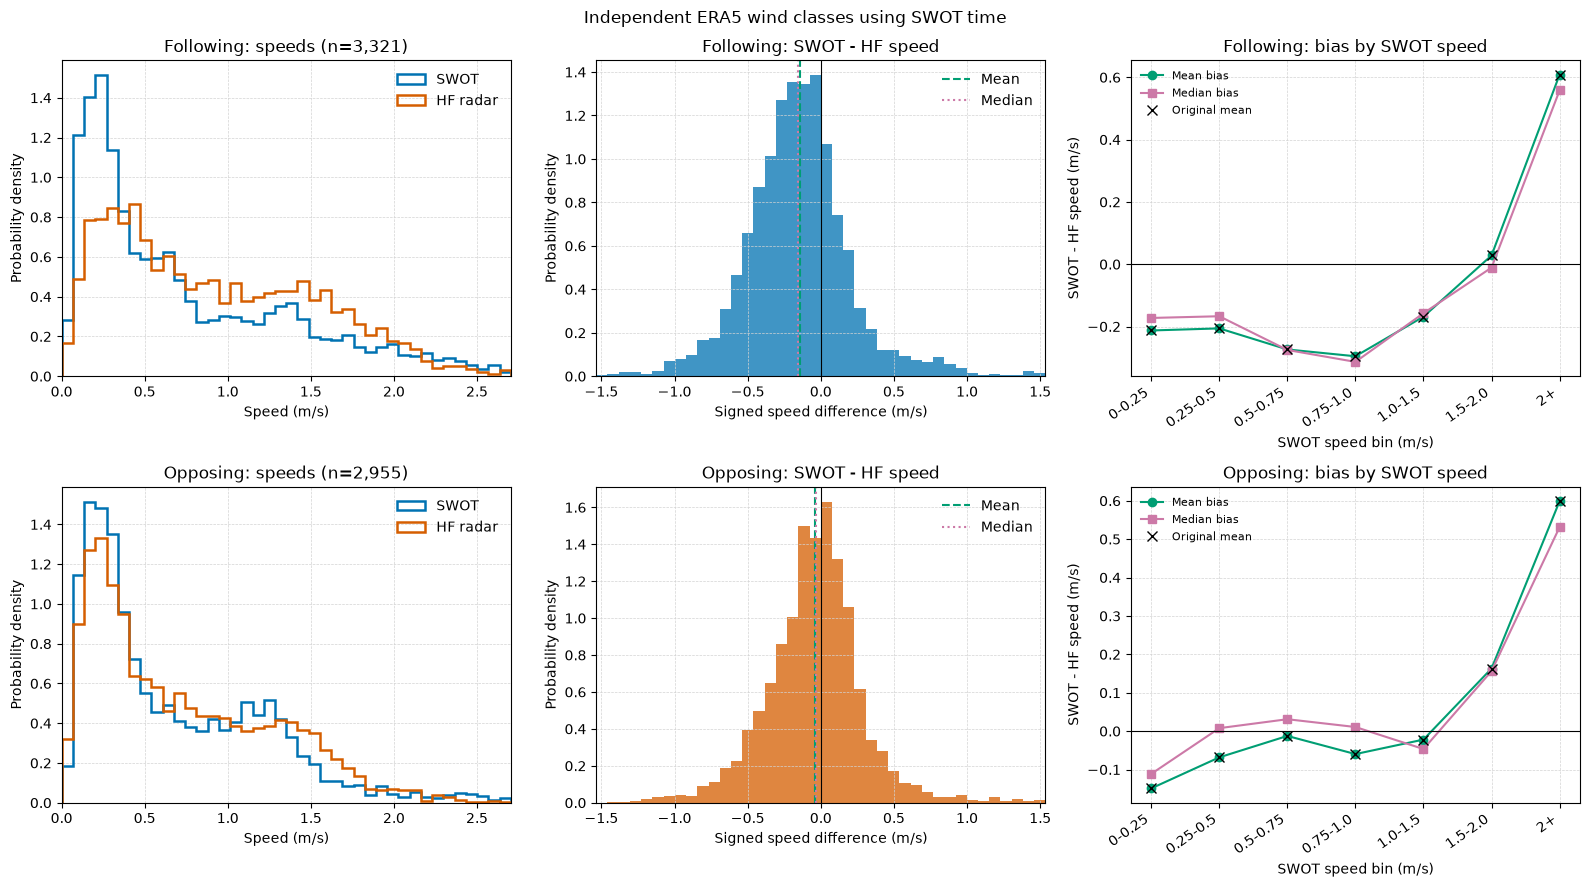

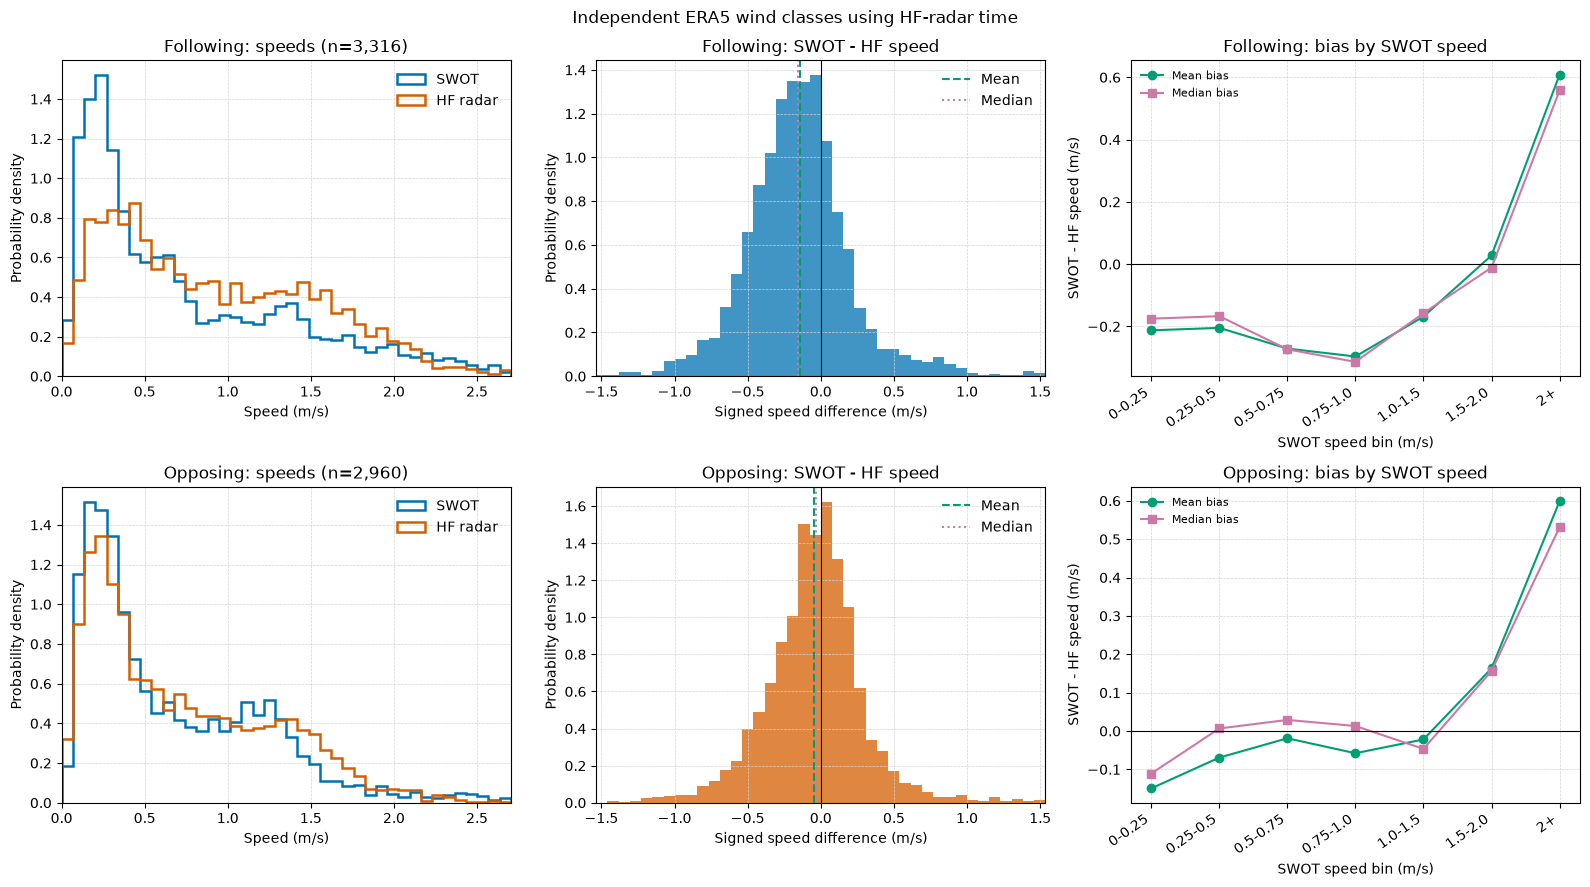

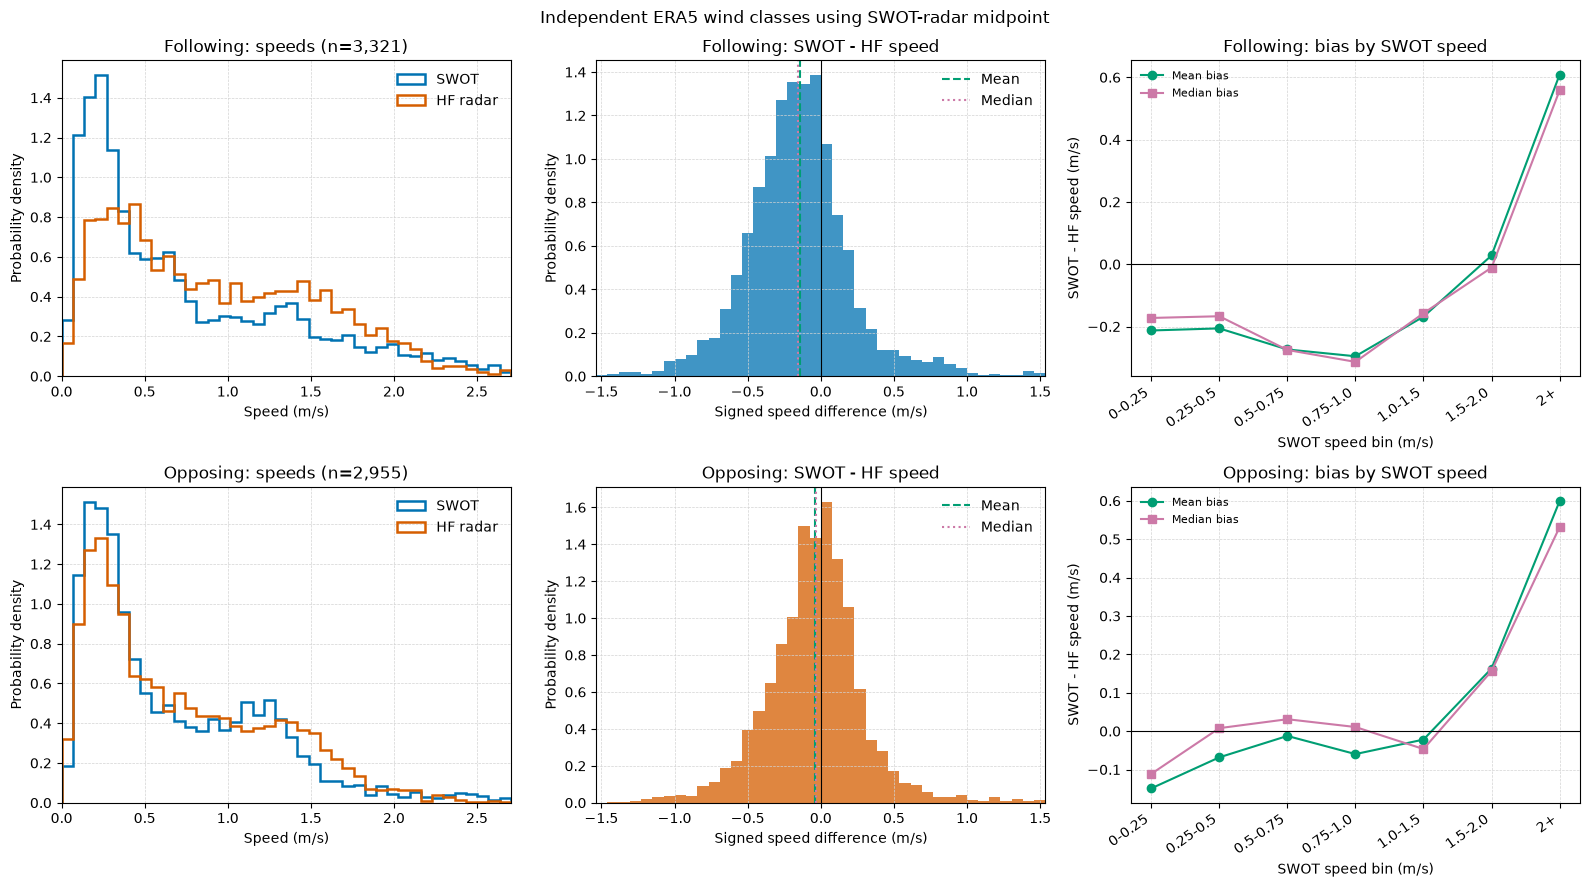

In [11]:
valid_speed_all = COMPARISON_MASK & speed_components_finite & np.isfinite(SWOT_SPEED) & np.isfinite(HF_SPEED)
speed_plot_limit = float(np.quantile(np.concatenate((SWOT_SPEED[valid_speed_all], HF_SPEED[valid_speed_all])), 0.995))
bias_plot_limit = float(np.quantile(np.abs(DELTA_SPEED[valid_speed_all]), 0.995))

for strategy_name in TIME_STRATEGIES:
    result = RESULTS[(strategy_name, 0.05)]
    figure, axes = plt.subplots(2, 3, figsize=(16, 9))
    for row_index, (class_name, class_mask, colour) in enumerate((
        ('Following', result['following'], '#0072B2'),
        ('Opposing', result['opposing'], '#D55E00'),
    )):
        axes[row_index, 0].hist(
            SWOT_SPEED[class_mask], bins=np.linspace(0, speed_plot_limit, 41),
            density=True, histtype='step', linewidth=1.8, label='SWOT', color='#0072B2',
        )
        axes[row_index, 0].hist(
            HF_SPEED[class_mask], bins=np.linspace(0, speed_plot_limit, 41),
            density=True, histtype='step', linewidth=1.8, label='HF radar', color='#D55E00',
        )
        axes[row_index, 0].set(
            title=f'{class_name}: speeds (n={int(class_mask.sum()):,})',
            xlabel='Speed (m/s)', ylabel='Probability density', xlim=(0, speed_plot_limit),
        )
        axes[row_index, 0].legend(frameon=False)

        class_bias = DELTA_SPEED[class_mask]
        axes[row_index, 1].hist(
            class_bias, bins=np.linspace(-bias_plot_limit, bias_plot_limit, 41),
            density=True, color=colour, alpha=0.75,
        )
        axes[row_index, 1].axvline(0, color='black', linewidth=0.8)
        if class_bias.size:
            axes[row_index, 1].axvline(np.mean(class_bias), color='#009E73', linestyle='--', label='Mean')
            axes[row_index, 1].axvline(np.median(class_bias), color='#CC79A7', linestyle=':', label='Median')
        axes[row_index, 1].set(
            title=f'{class_name}: SWOT - HF speed',
            xlabel='Signed speed difference (m/s)', ylabel='Probability density',
            xlim=(-bias_plot_limit, bias_plot_limit),
        )
        axes[row_index, 1].legend(frameon=False)

        bins_for_class = speed_bin_statistics.loc[
            (speed_bin_statistics['strategy'] == strategy_name)
            & (speed_bin_statistics['threshold_m_s'] == 0.05)
            & (speed_bin_statistics['wind_class'] == class_name)
        ]
        positions = np.arange(len(SPEED_BIN_LABELS))
        axes[row_index, 2].plot(
            positions, bins_for_class['mean_bias_m_s'], 'o-',
            color='#009E73', label='Mean bias',
        )
        axes[row_index, 2].plot(
            positions, bins_for_class['median_bias_m_s'], 's-',
            color='#CC79A7', label='Median bias',
        )
        axes[row_index, 2].axhline(0, color='black', linewidth=0.8)
        if strategy_name == 'SWOT time' and not original_speed_bin_table.empty:
            original_rows = original_speed_bin_table.loc[
                original_speed_bin_table['wind_class'].astype(str) == class_name
            ]
            if {'swot_speed_bin_m_s', 'mean_bias_swot_minus_hf_m_s'}.issubset(original_rows.columns):
                original_rows = original_rows.set_index('swot_speed_bin_m_s').reindex(SPEED_BIN_LABELS)
                axes[row_index, 2].plot(
                    positions, original_rows['mean_bias_swot_minus_hf_m_s'],
                    'x', color='black', markersize=7, label='Original mean',
                )
        axes[row_index, 2].set_xticks(positions, SPEED_BIN_LABELS, rotation=35, ha='right')
        axes[row_index, 2].set(
            title=f'{class_name}: bias by SWOT speed',
            xlabel='SWOT speed bin (m/s)', ylabel='SWOT - HF speed (m/s)',
        )
        axes[row_index, 2].legend(frameon=False, fontsize=8)
        for axis in axes[row_index]:
            axis.grid(color='lightgrey', linestyle='--', linewidth=0.5)
    figure.suptitle(f'Independent ERA5 wind classes using {strategy_name}')
    figure.tight_layout()
    plt.show()

## 16–17. Dependence-aware association and stratified checks

Estimate the association between along-current wind and HF-minus-SWOT velocity projected along the SWOT current. Confidence intervals resample whole overpasses, not grid cells. Also compare classes within current-speed bins, overpasses, and 0.5° spatial tiles. These are descriptive checks; sparse strata and non-random wind conditions limit adjustment and causal interpretation.

,n_grid_cell_observations,n_overpass_clusters,slope_m_per_m,slope_cluster_bootstrap_95_low,slope_cluster_bootstrap_95_high,intercept_m_s,intercept_cluster_bootstrap_95_low,intercept_cluster_bootstrap_95_high,pointwise_correlation_descriptive_only,bootstrap_replicates
0,6276,35,0.01574,0.00425,0.0253,-0.02737,-0.08528,0.03259,0.26275,3000


No pointwise p-value is used as independent-sample evidence. The interval resamples entire overpasses.


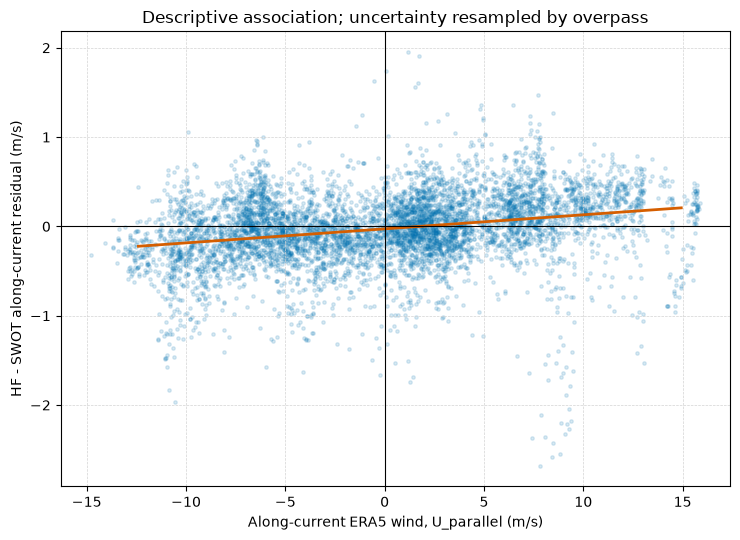

count    mean  median
speed_bin wind_class                       
0-0.25    Following     889 -0.2126 -0.1724
          Opposing      784 -0.1490 -0.1113
0.25-0.5  Following     720 -0.2060 -0.1669
          Opposing      734 -0.0682  0.0078
0.5-0.75  Following     456 -0.2736 -0.2752
          Opposing      337 -0.0125  0.0311
0.75-1.0  Following     256 -0.2954 -0.3135
          Opposing      275 -0.0597  0.0108
1.0-1.5   Following     504 -0.1683 -0.1573
          Opposing      604 -0.0220 -0.0465
1.5-2.0   Following     276  0.0282 -0.0108
          Opposing      135  0.1631  0.1563
2+        Following     220  0.6085  0.5579
          Opposing       86  0.5988  0.5312

,overpasses_with_both_classes,median_within_overpass_following_minus_opposing_bias_m_s,mean_within_overpass_following_minus_opposing_bias_m_s,q25_m_s,q75_m_s
0,25,-0.0632,-0.1306,-0.2687,0.0301


,0.5deg_tiles_with_both_classes,median_tile_following_minus_opposing_bias_m_s,mean_tile_following_minus_opposing_bias_m_s,q25_m_s,q75_m_s
0,26,-0.1112,-0.1164,-0.1827,-0.0283


Location tiles are coarse descriptive strata, not a spatially adjusted causal model. Empty and sparse strata are not inferred across.


In [12]:
PRIMARY_RESULT = RESULTS[('SWOT time', 0.05)]
REGRESSION_VALID = (
    COMPARISON_MASK & speed_components_finite
    & (SWOT_SPEED >= 0.05) & (SWOT_SPEED > 0)
    & PRIMARY['time_valid'][:, None, None]
    & PRIMARY['spatial_in_bounds']
    & np.isfinite(WIND_U) & np.isfinite(WIND_V)
    & np.isfinite(PRIMARY_RESULT['along_wind'])
    & np.isfinite(PRIMARY_RESULT['delta_u_parallel'])
)
regression_x = PRIMARY_RESULT['along_wind'][REGRESSION_VALID]
regression_y = PRIMARY_RESULT['delta_u_parallel'][REGRESSION_VALID]
regression_matches = np.broadcast_to(MATCH_IDS[:, None, None], COMPARISON_MASK.shape)[REGRESSION_VALID]

assert regression_x.size == regression_y.size == regression_matches.size
regression_slope, regression_intercept = np.polyfit(regression_x, regression_y, 1)
regression_r = float(np.corrcoef(regression_x, regression_y)[0, 1])

cluster_ids = np.unique(regression_matches)
cluster_statistics = []
for cluster_id in cluster_ids:
    cluster_mask = regression_matches == cluster_id
    x_values = regression_x[cluster_mask]
    y_values = regression_y[cluster_mask]
    cluster_statistics.append({
        'match': int(cluster_id),
        'n': int(cluster_mask.sum()),
        'sum_x': float(x_values.sum()),
        'sum_y': float(y_values.sum()),
        'sum_x2': float(np.dot(x_values, x_values)),
        'sum_xy': float(np.dot(x_values, y_values)),
    })
cluster_statistics = pd.DataFrame(cluster_statistics).set_index('match')

bootstrap_rng = np.random.default_rng(20261008)
bootstrap_replicates = 3000
cluster_count = len(cluster_statistics)
bootstrap_slopes = np.full(bootstrap_replicates, np.nan)
bootstrap_intercepts = np.full(bootstrap_replicates, np.nan)
cluster_sums = cluster_statistics[['n', 'sum_x', 'sum_y', 'sum_x2', 'sum_xy']].to_numpy(dtype=float)
for replicate in range(bootstrap_replicates):
    sampled_cluster_rows = cluster_sums[
        bootstrap_rng.integers(0, cluster_count, size=cluster_count)
    ]
    total_n, sum_x, sum_y, sum_x2, sum_xy = sampled_cluster_rows.sum(axis=0)
    denominator = sum_x2 - sum_x**2 / total_n
    if denominator > 0:
        bootstrap_slopes[replicate] = (sum_xy - sum_x * sum_y / total_n) / denominator
        bootstrap_intercepts[replicate] = (sum_y - bootstrap_slopes[replicate] * sum_x) / total_n
slope_interval = np.nanpercentile(bootstrap_slopes, [2.5, 97.5])
intercept_interval = np.nanpercentile(bootstrap_intercepts, [2.5, 97.5])
regression_result = pd.DataFrame([{
    'n_grid_cell_observations': regression_x.size,
    'n_overpass_clusters': cluster_count,
    'slope_m_per_m': regression_slope,
    'slope_cluster_bootstrap_95_low': slope_interval[0],
    'slope_cluster_bootstrap_95_high': slope_interval[1],
    'intercept_m_s': regression_intercept,
    'intercept_cluster_bootstrap_95_low': intercept_interval[0],
    'intercept_cluster_bootstrap_95_high': intercept_interval[1],
    'pointwise_correlation_descriptive_only': regression_r,
    'bootstrap_replicates': bootstrap_replicates,
}])
display(regression_result.round(5))
print('No pointwise p-value is used as independent-sample evidence. The interval resamples entire overpasses.')

figure, axis = plt.subplots(figsize=(7.5, 5.5))
plot_rng = np.random.default_rng(17)
plot_indices = np.arange(regression_x.size)
if plot_indices.size > 12000:
    plot_indices = plot_rng.choice(plot_indices, 12000, replace=False)
axis.scatter(regression_x[plot_indices], regression_y[plot_indices], s=6, alpha=0.15, color='#0072B2', rasterized=True)
line_x = np.linspace(np.nanpercentile(regression_x, 1), np.nanpercentile(regression_x, 99), 100)
axis.plot(line_x, regression_intercept + regression_slope * line_x, color='#D55E00', linewidth=2)
axis.axhline(0, color='black', linewidth=0.8)
axis.axvline(0, color='black', linewidth=0.8)
axis.set_xlabel('Along-current ERA5 wind, U_parallel (m/s)')
axis.set_ylabel('HF - SWOT along-current residual (m/s)')
axis.set_title('Descriptive association; uncertainty resampled by overpass')
axis.grid(color='lightgrey', linestyle='--', linewidth=0.5)
figure.tight_layout()
plt.show()

# Stratify the speed-bias comparison using the same cell observations and time strategy.
stratified_frame = pd.DataFrame({
    'match': np.broadcast_to(MATCH_IDS[:, None, None], COMPARISON_MASK.shape)[PRIMARY_RESULT['eligible']],
    'latitude': np.broadcast_to(matched_latitude[None, :, None], COMPARISON_MASK.shape)[PRIMARY_RESULT['eligible']],
    'longitude': np.broadcast_to(matched_longitude[None, None, :], COMPARISON_MASK.shape)[PRIMARY_RESULT['eligible']],
    'swot_speed': SWOT_SPEED[PRIMARY_RESULT['eligible']],
    'bias': DELTA_SPEED[PRIMARY_RESULT['eligible']],
    'wind_class': np.where(PRIMARY_RESULT['following'][PRIMARY_RESULT['eligible']], 'Following', 'Opposing'),
})
stratified_frame['speed_bin'] = pd.cut(
    stratified_frame['swot_speed'], bins=SPEED_BIN_EDGES,
    labels=SPEED_BIN_LABELS, right=False, include_lowest=True,
)
current_speed_strata = stratified_frame.groupby(['speed_bin', 'wind_class'], observed=True)['bias'].agg(['count', 'mean', 'median'])
display(current_speed_strata.round(4))

per_overpass = stratified_frame.groupby(['match', 'wind_class'], observed=True)['bias'].agg(['count', 'mean'])
overpass_pivot = per_overpass['mean'].unstack('wind_class').dropna(subset=['Following', 'Opposing'])
overpass_contrasts = overpass_pivot['Following'] - overpass_pivot['Opposing']
overpass_stratified_summary = pd.DataFrame([{
    'overpasses_with_both_classes': len(overpass_contrasts),
    'median_within_overpass_following_minus_opposing_bias_m_s': float(overpass_contrasts.median()) if len(overpass_contrasts) else np.nan,
    'mean_within_overpass_following_minus_opposing_bias_m_s': float(overpass_contrasts.mean()) if len(overpass_contrasts) else np.nan,
    'q25_m_s': float(overpass_contrasts.quantile(0.25)) if len(overpass_contrasts) else np.nan,
    'q75_m_s': float(overpass_contrasts.quantile(0.75)) if len(overpass_contrasts) else np.nan,
}])
display(overpass_stratified_summary.round(4))

latitude_edges = np.arange(np.floor(matched_latitude.min() * 2) / 2, np.ceil(matched_latitude.max() * 2) / 2 + 0.5, 0.5)
longitude_edges = np.arange(np.floor(matched_longitude.min() * 2) / 2, np.ceil(matched_longitude.max() * 2) / 2 + 0.5, 0.5)
stratified_frame['latitude_tile'] = pd.cut(stratified_frame['latitude'], bins=latitude_edges, include_lowest=True)
stratified_frame['longitude_tile'] = pd.cut(stratified_frame['longitude'], bins=longitude_edges, include_lowest=True)
location_group = stratified_frame.groupby(['latitude_tile', 'longitude_tile', 'wind_class'], observed=True)['bias'].agg(['count', 'mean'])
location_pivot = location_group['mean'].unstack('wind_class').dropna(subset=['Following', 'Opposing'])
location_contrasts = location_pivot['Following'] - location_pivot['Opposing']
location_stratified_summary = pd.DataFrame([{
    '0.5deg_tiles_with_both_classes': len(location_contrasts),
    'median_tile_following_minus_opposing_bias_m_s': float(location_contrasts.median()) if len(location_contrasts) else np.nan,
    'mean_tile_following_minus_opposing_bias_m_s': float(location_contrasts.mean()) if len(location_contrasts) else np.nan,
    'q25_m_s': float(location_contrasts.quantile(0.25)) if len(location_contrasts) else np.nan,
    'q75_m_s': float(location_contrasts.quantile(0.75)) if len(location_contrasts) else np.nan,
}])
display(location_stratified_summary.round(4))
print('Location tiles are coarse descriptive strata, not a spatially adjusted causal model. Empty and sparse strata are not inferred across.')

## 18. PASS / FAIL / REVIEW scorecard

The verdicts below distinguish reproducibility from scientific interpretation. A reproducible association is not evidence that wind caused the velocity difference, and this analysis alone cannot rule out Stokes drift or other processes.

In [13]:
primary_time_row = time_audit.loc['SWOT time']
time_match_verdict = (
    'PASS'
    if primary_time_row['valid_within_90min'] == MATCH_COUNT
    and primary_time_row['missing_or_out_of_tolerance'] == 0
    and ERA5_TIMES.is_unique
    else 'FAIL'
)
spatial_verdict = (
    'PASS'
    if max_manual_error <= 1e-6
    and all(collocation['u10'].shape == COMPARISON_MASK.shape for collocation in COLLOCATIONS.values())
    and all(not np.isfinite(collocation['u10'][~collocation['spatial_in_bounds']]).any() for collocation in COLLOCATIONS.values())
    else 'FAIL'
)
vector_verdict = (
    'PASS'
    if east_projection[0] > 0 and east_projection[1] < 0 and synthetic_delta_along > 0
    else 'FAIL'
)

reproduction_verdict = 'REVIEW'
reproduction_evidence = 'Saved original class summary could not be parsed from notebook outputs.'
if not original_class_table.empty:
    original_for_verdict = original_class_table.copy()
    if 'wind_class' not in original_for_verdict.columns:
        original_for_verdict = original_for_verdict.rename(columns={original_for_verdict.columns[0]: 'wind_class'})
    original_for_verdict['wind_class'] = original_for_verdict['wind_class'].astype(str)
    original_for_verdict = original_for_verdict.set_index('wind_class')
    shared_classes = set(original_for_verdict.index) & set(primary_class_statistics.index)
    if {'Following', 'Opposing'}.issubset(shared_classes) and 'n' in original_for_verdict.columns:
        counts_match = all(
            int(original_for_verdict.loc[class_name, 'n']) == int(primary_class_statistics.loc[class_name, 'n'])
            for class_name in ('Following', 'Opposing')
        )
        mean_column = 'mean_bias_swot_minus_hf_m_s'
        means_match = (
            mean_column in original_for_verdict.columns
            and max(
                abs(float(original_for_verdict.loc[class_name, mean_column])
                    - float(primary_class_statistics.loc[class_name, mean_column]))
                for class_name in ('Following', 'Opposing')
            ) <= 0.0015
        )
        reproduction_verdict = 'PASS' if counts_match and means_match else 'FAIL'
        reproduction_evidence = (
            f'Counts match: {counts_match}; means within 0.0015 m/s: {means_match}; '
            f"recomputed n={primary_class_statistics['n'].to_dict()}"
        )

scorecard = pd.DataFrame([
    {
        'check': 'Time matching',
        'verdict': time_match_verdict,
        'checks': 'Every stored swot_time nearest ERA5 timestamp within 90 min; unique sorted ERA5 index; offsets and radar/midpoint alternatives tabulated.',
        'evidence': f"{int(primary_time_row['valid_within_90min'])}/{MATCH_COUNT} SWOT clocks valid; median offset {primary_time_row['offset_median_minutes']:.1f} min; max {primary_time_row['offset_max_minutes']:.1f} min.",
        'discrepancy': f"Duplicate source ERA5 records removed: {len(ERA5_RAW_DUPLICATE_TIMES)}; radar/midpoint class changes appear in strategy_comparison.",
    },
    {
        'check': 'Spatial interpolation',
        'verdict': spatial_verdict,
        'checks': 'Ascending regular source coordinates; match-lat/lon dimension order; bounds-masked interpolation; deterministic manual bilinear checks.',
        'evidence': f'{len(manual_interpolation_checks)} sample points; maximum component absolute error {max_manual_error:.3g} m/s; ERA5 grid {len(ERA5_LATITUDE)} x {len(ERA5_LONGITUDE)}.',
        'discrepancy': f"Out-of-bounds matched grid cells: {int((~wind_bounds_valid & COMPARISON_MASK).sum())}.",
    },
    {
        'check': 'Vector projection',
        'verdict': vector_verdict,
        'checks': 'Synthetic east/north, following/opposing/cross-current, zero/near-zero, NaN and shape checks; HF-minus-SWOT along-current sign test.',
        'evidence': 'East/north convention; positive U_parallel follows the SWOT current; positive delta_U_parallel means HF has larger along-current velocity.',
        'discrepancy': 'Direction is undefined for zero or below-threshold SWOT speed and is excluded.',
    },
    {
        'check': 'Main-result reproduction',
        'verdict': reproduction_verdict,
        'checks': 'Independent class recomputation from local Zarr and ERA5; compare saved cell-52 output; alternate clocks and four speed thresholds included.',
        'evidence': reproduction_evidence,
        'discrepancy': 'See reproduction_comparison, strategy_comparison, sensitivity_matrix and stratified outputs.',
    },
])
display(scorecard)
print('Final verdicts:')
for row in scorecard.itertuples(index=False):
    print(f"{row.verdict}: {row.check} -- {row.evidence}")
print('Wind-class contrasts and regression remain descriptive; this analysis makes no causal claim and does not rule out Stokes drift.')

,check,verdict,checks,evidence,discrepancy
0,Time matching,PASS,Every stored swot_time nearest ERA5 timestamp ...,35/35 SWOT clocks valid; median offset 9.1 min...,Duplicate source ERA5 records removed: 0; rada...
1,Spatial interpolation,PASS,Ascending regular source coordinates; match-la...,12 sample points; maximum component absolute e...,Out-of-bounds matched grid cells: 0.
2,Vector projection,PASS,"Synthetic east/north, following/opposing/cross...",East/north convention; positive U_parallel fol...,Direction is undefined for zero or below-thres...
3,Main-result reproduction,PASS,Independent class recomputation from local Zar...,Counts match: True; means within 0.0015 m/s: T...,"See reproduction_comparison, strategy_comparis..."


Final verdicts:
PASS: Time matching -- 35/35 SWOT clocks valid; median offset 9.1 min; max 24.8 min.
PASS: Spatial interpolation -- 12 sample points; maximum component absolute error 1.78e-15 m/s; ERA5 grid 20 x 44.
PASS: Vector projection -- East/north convention; positive U_parallel follows the SWOT current; positive delta_U_parallel means HF has larger along-current velocity.
PASS: Main-result reproduction -- Counts match: True; means within 0.0015 m/s: True; recomputed n={'Following': 3321, 'Opposing': 2955}
Wind-class contrasts and regression remain descriptive; this analysis makes no causal claim and does not rule out Stokes drift.


In [14]:
FINAL_INPUT_FINGERPRINTS = {
    str(path): {'sha256': sha256(path), 'modified_ns': path.stat().st_mtime_ns}
    for path in AUDIT_INPUT_FILES
}
changed_inputs = [
    path for path, initial in INITIAL_INPUT_FINGERPRINTS.items()
    if FINAL_INPUT_FINGERPRINTS.get(path) != initial
]
input_integrity = pd.DataFrame([
    {
        'file': path,
        'unchanged_hash_and_mtime': FINAL_INPUT_FINGERPRINTS.get(path) == initial,
    }
    for path, initial in INITIAL_INPUT_FINGERPRINTS.items()
])
display(input_integrity)
assert not changed_inputs, f'Read-only source integrity check failed: {changed_inputs}'
print('All fingerprinted source notebook, ERA5 files and matched-Zarr metadata remained unchanged.')

,file,unchanged_hash_and_mtime
0,/not...,True
1,/dat...,True
2,/dat...,True
3,/dat...,True
4,/dat...,True
5,/dat...,True
6,/dat...,True
7,/dat...,True
8,/dat...,True
9,/dat...,True


All fingerprinted source notebook, ERA5 files and matched-Zarr metadata remained unchanged.
